# Projet Data Mining : analyse des données `health`

* Groupe : Groupe 10

Ce notebook part des fichiers nettoyés (`data/health_clean/`) et suit l'ordre des cours.

*Usage de l'IA générative : ce travail a été fait avec l'aide de Claude (Anthropic). L'assistant a écrit la plus grande partie du code et des textes, et a proposé des méthodes et des pistes d'interprétation. De notre côté, on a choisi les étapes, discuté et validé chaque décision de nettoyage et d'analyse, relu les résultats, et demandé des corrections quand un chiffre ou une interprétation ne tenait pas.*

## Cours 1 : Comprendre ses données

### 1.1 Tableaux d'analyse

14 mesures sont prises à chaque consultation, 18 une seule fois par patient. On travaille donc sur deux tableaux : un par consultation (1 067 lignes) et un par patient (240 lignes, avec la médiane des mesures répétées).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
D = Path("../data/health_clean")

P = pd.read_csv(D / "patient_administration.csv", parse_dates=["date_of_birth"])
E = pd.read_csv(D / "clinical_encounters.csv", parse_dates=["encounter_start", "encounter_end"])
O = pd.read_csv(D / "clinical_observations.csv")
PR = pd.read_csv(D / "clinical_procedures.csv")
W = pd.read_csv(D / "observations_wide.csv", parse_dates=["encounter_start"])
CAT = pd.read_csv(D / "observation_catalog.csv").set_index("observation_code")

REPETEES = CAT.index[(CAT["n_mesures"] > 241) & (CAT["type"] == "nombre")].tolist()
UNIQUES = CAT.index[(CAT["n_mesures"] <= 241) & (CAT["type"] == "nombre")].tolist()

conso = W.merge(P[["patient_number", "date_of_birth"]], on="patient_number")
conso["AGE"] = (conso["encounter_start"] - conso["date_of_birth"]).dt.days / 365.25
conso = conso[["encounter_number", "patient_number"] + REPETEES + ["AGE"]]

ordinal = {"none": 0, "mild": 1, "moderate": 2, "severe": 3}
patient = (O[O["observation_code"].isin(UNIQUES)].pivot(index="patient_number", columns="observation_code", values="numeric_value")
           .join(O[O["observation_code"].isin(["MUSC", "NEURO"])]
                 .pivot(index="patient_number", columns="observation_code", values="text_value").apply(lambda c: c.map(ordinal)))
           .join(conso.groupby("patient_number")[REPETEES + ["AGE"]].median()))
print("par consultation :", conso.shape, "| par patient :", patient.shape)

par consultation : (1067, 16) | par patient : (240, 30)


### 1.2 Types de variables

* Numériques continues : les mesures (pouls, âges, scores…) ; discrète : `AGECOND` (nombre d'affections).
* Nominales ordonnées : `MUSC`, `NEURO` (none < mild < moderate < severe), traitées comme des nombres de 0 à 3 ; la confidentialité (standard < confidential < restricted).
* Nominales non ordonnées : sexe, région, profession, type de consultation, clinique, acte, `OCULAR`, `VESTIB`, `BINOCOORD`.
* Les dates et les notes seront traitées aux cours 5 et 6.

### 1.3 Variables numériques

Pour chaque mesure : moyenne et écart-type, médiane avec min, max et quartiles. La colonne « forme » résume l'histogramme sans l'afficher.

In [2]:
variables = {c: conso[c] for c in REPETEES} | {c: patient[c] for c in UNIQUES}

def forme(s):
    s = s.dropna()
    if max((s == s.min()).mean(), (s == s.max()).mean()) > 0.03:
        return "bloquée à une limite"
    if abs(s.skew()) < 0.5:
        return "symétrique"
    return "étirée vers le bas" if s.skew() < 0 else "étirée vers le haut"

stats = pd.DataFrame({c: {"nom": CAT.loc[c, "nom"], "moyenne": s.mean(), "écart-type": s.std(), "médiane": s.median(),
                          "min": s.min(), "Q1": s.quantile(.25), "Q3": s.quantile(.75), "max": s.max(), "forme": forme(s)}
                      for c, s in variables.items()}).T
with pd.option_context("display.float_format", "{:.2f}".format, "display.max_rows", 40):
    display(stats.sort_values("forme"))

,nom,moyenne,écart-type,médiane,min,Q1,Q3,max,forme
AGECOND,Age-related condition count,0.98,0.91,1.00,0.00,0.00,2.00,4.00,bloquée à une limite
BALANCE,Balance score,76.40,12.96,76.80,38.90,67.90,85.20,100.00,bloquée à une limite
THERMQUAL,Thermal detection quality,89.40,7.50,90.25,58.20,85.55,95.08,100.00,bloquée à une limite
COGNITIVE,Cognitive score,86.32,8.59,87.10,57.20,81.20,92.60,100.00,bloquée à une limite
IDCONS,Identity consistency score,92.19,7.15,93.20,36.30,89.80,96.45,100.00,bloquée à une limite
GAITSYM,Gait symmetry index,80.78,11.92,81.65,38.50,73.90,88.60,100.00,bloquée à une limite
THORPEAK,Thoracic secondary peak index,28.74,17.90,26.85,0.00,15.50,40.00,85.40,bloquée à une limite
CAMMATCH,Camera match confidence,89.38,9.36,91.25,40.60,84.83,95.80,100.00,bloquée à une limite
VALEFT,Left visual acuity,0.93,0.08,0.93,0.68,0.88,0.98,1.15,symétrique
SYSBP,Systolic blood pressure,121.66,12.87,121.05,88.00,113.22,128.50,155.30,symétrique


* La plupart des mesures physiologiques sont symétriques (proches d'une loi normale).
* Beaucoup de scores plafonnent à 100 (équilibre, cognition, caméra, identité…) : ces variables sont tronquées.
* `IDCONS` et `CAMMATCH` sont presque toujours élevés, avec quelques patients très bas. `BIOAGE` descend jusqu'à 11 ans alors que les patients ont tous au moins 15 ans.

### 1.4 Variables nominales

In [3]:
nominales = {
    "sexe": P["registered_sex"], "région": P["home_region"],
    "profession détaillée": P["occupation_detaillee"], "clinique": P["primary_facility_license"],
    "orientée par": E["referral_source"], "confidentialité": E["confidentiality_class"], "type d'acte": PR["procedure_code"],
} | {c: O.loc[O["observation_code"] == c, "text_value"] for c in ["OCULAR", "VESTIB", "BINOCOORD"]}

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame([{"variable": nom, "répartition": ", ".join(f"{k} ({v})" for k, v in s.value_counts().items())}
                          for nom, s in nominales.items()]))

,variable,répartition
0,sexe,"female (96), male (93), nonbinary (51)"
1,région,"Avelora Federation (54), Nordhaven Union (52), Valenne Republic (48), Kintara Republic (47), Tembara Commonwealth (39)"
2,profession détaillée,"False (187), True (53)"
3,clinique,"FAC-VLN-101 (150), FAC-AVL-201 (64), FAC-AVL-301 (26)"
4,orientée par,"executive health office (226), self (217), research programme (213), primary care (205), occupational service (203)"
5,confidentialité,"standard (581), confidential (295), restricted (191)"
6,type d'acte,"OCT-TRK (51), MRP-42 (50), OCC-PNL (49), AUT-REV (43), CARD-IMG (41), AGE-PNL (39), MOB-PNL (37)"
7,OCULAR,"inconclusive (455), normal (413), atypical (42)"
8,VESTIB,"normal (169), inconclusive (60), abnormal (11)"
9,BINOCOORD,"normal (148), reduced (78), atypical (14)"


Les patients sont bien répartis entre sexes et régions. Les cinq origines d'orientation sont à égalité (~210 chacune) : l'« executive health office », réservé aux dirigeants, est aussi fréquent que le médecin traitant. Près de la moitié des consultations sont confidentielles ou restreintes.

### 1.5 Corrélations : Pearson et Spearman

* Pearson mesure une relation en ligne droite et est sensible aux valeurs extrêmes.
* Spearman travaille sur les rangs : il détecte toute relation qui monte ou descend, et les points extrêmes l'influencent peu.

On compare les deux sur les mesures de consultation. Un écart entre les deux cartes signale une relation portée par quelques points.

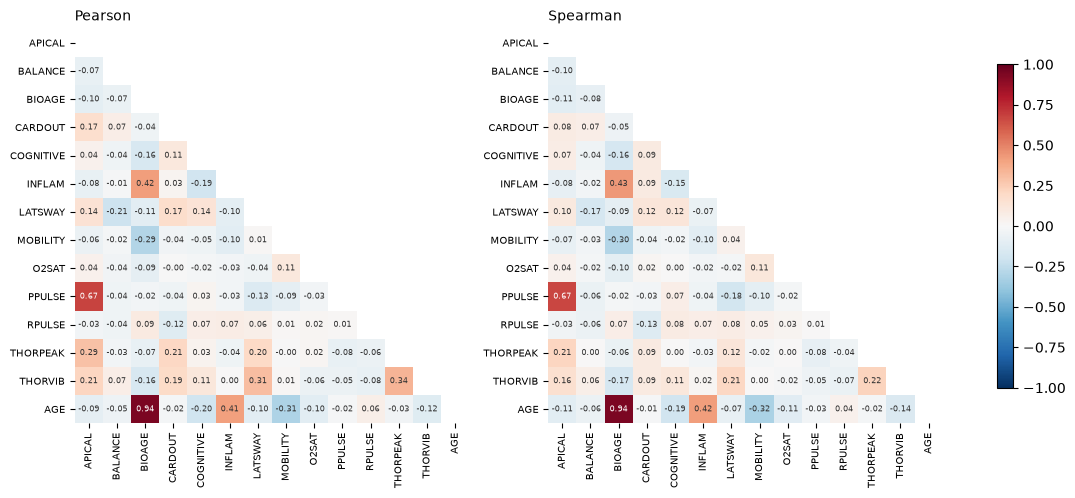

In [4]:
def carte(corr, titre, ax):
    masque = np.triu(np.ones_like(corr, dtype=bool))
    im = ax.imshow(corr.mask(masque), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr)), corr.index, fontsize=7)
    for i in range(len(corr)):
        for j in range(i):
            v = corr.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > .6 else "#333")
    ax.set_title(titre, fontsize=10, loc="left")
    for side in ax.spines.values():
        side.set_visible(False)
    return im

num = conso[REPETEES + ["AGE"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
carte(num.corr("pearson"), "Pearson", axes[0])
im = carte(num.corr("spearman"), "Spearman", axes[1])
fig.colorbar(im, ax=axes, shrink=.7)
plt.show()

Au niveau patient (30 variables), une carte serait illisible. On liste donc seulement les paires les plus liées, puis celles où les deux coefficients diffèrent le plus.

In [5]:
def paires(tab, niveau):
    s, p = tab.corr("spearman"), tab.corr("pearson")
    return pd.DataFrame([(niveau, a, b, p.loc[a, b], s.loc[a, b])
                         for i, a in enumerate(tab.columns) for b in tab.columns[i + 1:]],
                        columns=["niveau", "variable 1", "variable 2", "pearson", "spearman"])

toutes = pd.concat([paires(num, "consultation"), paires(patient, "patient")])
toutes["écart"] = toutes["pearson"] - toutes["spearman"]
display(toutes[toutes["spearman"].abs() >= .35].sort_values("spearman", key=abs, ascending=False).round(2))
display(toutes.sort_values("écart", key=abs, ascending=False).head(5).round(2))

,niveau,variable 1,variable 2,pearson,spearman,écart
379,patient,BIOAGE,AGE,0.95,0.95,-0.00
35,consultation,BIOAGE,AGE,0.94,0.94,-0.00
352,patient,APICAL,PPULSE,0.76,0.75,0.00
308,patient,WALKSPD,MOBILITY,0.73,0.71,0.02
8,consultation,APICAL,PPULSE,0.67,0.67,0.00
371,patient,BIOAGE,INFLAM,0.43,0.45,-0.01
406,patient,INFLAM,AGE,0.43,0.44,-0.01
27,consultation,BIOAGE,INFLAM,0.42,0.43,-0.01
28,patient,AGECOND,AGE,0.42,0.42,-0.01
17,patient,AGECOND,BIOAGE,0.41,0.42,-0.01


,niveau,variable 1,variable 2,pearson,spearman,écart
32,patient,CAMMATCH,IDCONS,0.46,0.18,0.28
148,patient,IDCONS,CARDOUT,-0.29,-0.11,-0.18
157,patient,IDCONS,THORVIB,-0.27,-0.09,-0.17
46,patient,CAMMATCH,CARDOUT,-0.22,-0.08,-0.14
432,patient,THORPEAK,THORVIB,0.31,0.18,0.13


* Les seuls liens forts sont attendus : âge biologique / âge réel (0,95), pouls au cœur / au poignet (0,75), vitesse de marche / mobilité (0,71). Toutes les autres mesures sont presque indépendantes.
* Pour caméra / identité, Pearson vaut 0,46 mais Spearman seulement 0,18. Le lien est donc porté par quelques patients qui ont les deux valeurs très basses, pas par l'ensemble.

### 1.6 Balayage élargi : près de 90 variables par patient

Pour ne rien rater, on construit près de 90 variables par patient à partir de tous les fichiers :
* pour chaque mesure : sa médiane, sa variabilité d'une visite à l'autre (écart-type) et son évolution dans le temps (pente par an) ;
* les comptages d'anomalies : pouls « discordant », suivi oculaire atypique, valeurs hors norme… ;
* les consultations (nombre, durée, confidentialité, types, origine), les actes par type, les enregistrements cardiaques et les notes.

On calcule ensuite Pearson et Spearman sur toutes les paires (environ 3 700) et on ne garde que les plus fortes. On écarte les paires évidentes, comme une mesure et sa propre variabilité.

In [6]:
PR = pd.read_csv(D / "clinical_procedures.csv")
CR = pd.read_csv(D / "cardiac_recordings.csv")
N = pd.read_csv(D / "clinical_notes.csv")

W2 = conso.merge(W[["encounter_number", "encounter_start"]], on="encounter_number")
W2["ECART_AGE"] = W2["BIOAGE"] - W2["AGE"]
W2["ECART_POULS"] = W2["APICAL"] - W2["PPULSE"]
W2["T"] = (W2["encounter_start"] - pd.Timestamp("2014-01-01")).dt.days / 365.25
W2 = W2.sort_values(["patient_number", "encounter_start"])
g = W2.groupby("patient_number")

def pente(d, col):
    d = d[["T", col]].dropna()
    return np.polyfit(d["T"], d[col], 1)[0] if len(d) >= 3 else np.nan

feat = g[REPETEES + ["AGE", "ECART_AGE", "ECART_POULS"]].median()
feat = feat.join(g[REPETEES + ["ECART_POULS"]].std().add_suffix("_STD"))
for c in ["BIOAGE", "INFLAM", "MOBILITY", "COGNITIVE", "LATSWAY", "THORPEAK", "ECART_POULS", "CARDOUT"]:
    feat[c + "_PENTE"] = g.apply(lambda d: pente(d, c))
avec_age = W2.dropna(subset=["ECART_AGE"])
feat["CHUTE_MAX_AGE"] = avec_age.groupby("patient_number")["ECART_AGE"].diff().groupby(avec_age["patient_number"]).min()
feat = feat.join(patient[UNIQUES + ["MUSC", "NEURO"]])

txt = O[O["text_value"].notna()]
compte = lambda masque: O[masque].groupby("patient_number").size()
feat["N_OCULAR_ATYP"] = compte((O["observation_code"] == "OCULAR") & (O["text_value"] == "atypical"))
feat["BINOCOORD_ATYP"] = compte((O["observation_code"] == "BINOCOORD") & (O["text_value"] == "atypical"))
feat["VESTIB_ANORMAL"] = compte((O["observation_code"] == "VESTIB") & (O["text_value"] == "abnormal"))
feat["N_DISCORDANT"] = compte(O["interpretation_code"] == "discordant")
feat["N_REVIEW"] = compte(O["interpretation_code"] == "review")
feat["N_HORS_PLAGE"] = compte(O["hors_plage_ref"])

E["duree"] = (E["encounter_end"] - E["encounter_start"]).dt.total_seconds() / 60
ge = E.groupby("patient_number")
feat["NB_CONSULT"] = ge.size()
feat["DUREE_MOY"] = ge["duree"].mean()
feat["PART_CONFID"] = ge["confidentiality_class"].apply(lambda s: (s != "standard").mean())
for t in E["encounter_type"].unique():
    feat["CONSULT_" + t] = E[E["encounter_type"] == t].groupby("patient_number").size()
for r in E["referral_source"].dropna().unique():
    feat["ORIENTE_" + r.replace(" ", "_")] = E[E["referral_source"] == r].groupby("patient_number").size()
for c in PR["procedure_code"].unique():
    feat["ACTE_" + c] = PR[PR["procedure_code"] == c].groupby("patient_number").size()
feat["N_ENREG_CARDIO"] = CR.groupby("patient_number").size()
feat["N_NOTES"] = N.groupby("patient_number").size()
comptes = [c for c in feat.columns if c.startswith(("N_", "CONSULT_", "ORIENTE_", "ACTE_", "BINOCOORD_", "VESTIB_"))]
feat[comptes] = feat[comptes].fillna(0)
print("variables par patient :", feat.shape[1])

s, p = feat.corr("spearman"), feat.corr("pearson")
racine = lambda v: v.split("_")[0]
balayage = pd.DataFrame([(a, b, p.loc[a, b], s.loc[a, b]) for i, a in enumerate(feat.columns) for b in feat.columns[i + 1:]
                         if racine(a) != racine(b)], columns=["variable 1", "variable 2", "pearson", "spearman"]).dropna()
balayage["écart"] = balayage["pearson"] - balayage["spearman"]
print("paires testées :", len(balayage))
display(balayage.sort_values("spearman", key=abs, ascending=False).head(15).round(2))
display(balayage.sort_values("écart", key=abs, ascending=False).head(6).round(2))

variables par patient : 88
paires testées : 3704


,variable 1,variable 2,pearson,spearman,écart
181,BIOAGE,AGE,0.95,0.95,-0.00
3303,BINOCOORD_ATYP,CONSULT_ocular_assessment,0.67,0.81,-0.14
3636,CONSULT_research_procedure,ACTE_MRP-42,0.33,0.80,-0.47
3359,N_DISCORDANT,CONSULT_cardiac_assessment,0.69,0.75,-0.07
8,APICAL,PPULSE,0.76,0.75,0.00
3331,VESTIB_ANORMAL,CONSULT_mobility_assessment,0.89,0.72,0.17
618,MOBILITY,WALKSPD,0.73,0.71,0.02
1429,BIOAGE_STD,NB_CONSULT,0.68,0.69,-0.01
3267,N_OCULAR_ATYP,BINOCOORD_ATYP,0.67,0.68,-0.01
3274,N_OCULAR_ATYP,CONSULT_ocular_assessment,0.57,0.65,-0.09


,variable 1,variable 2,pearson,spearman,écart
3636,CONSULT_research_procedure,ACTE_MRP-42,0.33,0.80,-0.47
3663,ORIENTE_executive_health_office,ACTE_MRP-42,0.58,0.14,0.44
3465,DUREE_MOY,CONSULT_specialist_procedure,0.73,0.31,0.42
1406,BIOAGE_STD,CHUTE_MAX_AGE,-0.65,-0.23,-0.42
2599,CHUTE_MAX_AGE,CONSULT_executive_health_review,-0.87,-0.45,-0.42
3469,DUREE_MOY,ORIENTE_executive_health_office,0.42,0.02,0.40


Au-delà des liens attendus, le balayage fait ressortir deux choses :
* Les anomalies vont avec des examens ciblés. Coordination des yeux atypique et bilans oculaires (0,81), pouls discordants et bilans cardiaques (0,75), test d'équilibre anormal et bilans de mobilité (0,72). Certains patients sont donc suivis de près précisément pour ces anomalies.
* Les chutes brutales d'âge biologique d'une visite à l'autre (`CHUTE_MAX_AGE`) vont avec le nombre de « executive health reviews » (Pearson −0,87, mais Spearman −0,45). C'est donc encore le fait de quelques patients. Les consultations « procédure » et « recherche » vont, elles, avec l'acte `MRP-42`. On regarde cet acte de plus près.

### 1.7 Zoom sur l'acte `MRP-42`

In [7]:
feat["NB_MRP42"] = feat["ACTE_MRP-42"]
groupe = feat["NB_MRP42"].map(lambda n: "0 dose" if n == 0 else ("1 dose" if n == 1 else "3 doses ou plus"))
mrp = PR[PR["procedure_code"] == "MRP-42"].join(feat["NB_MRP42"], on="patient_number")
display(pd.crosstab(mrp["NB_MRP42"].map(lambda n: "1 dose" if n == 1 else "3 doses ou plus"), mrp["authorization_class"]))
display(feat.groupby(groupe)[["ECART_AGE", "BIOAGE_PENTE", "NB_CONSULT", "DUREE_MOY", "AGE"]].median().round(2)
        .assign(patients=groupe.value_counts()))
display(feat.loc[feat["NB_MRP42"] >= 3, ["NB_MRP42", "AGE", "ECART_AGE", "BIOAGE_PENTE"]].round(1)
        .join(P.set_index("patient_number")["occupation_text"]).sort_values("ECART_AGE"))

authorization_class,research_restricted,restricted_specialist
NB_MRP42,,
1 dose,20,0
3 doses ou plus,0,30


,ECART_AGE,BIOAGE_PENTE,NB_CONSULT,DUREE_MOY,AGE,patients
NB_MRP42,,,,,,
0 dose,-1.26,1.00,4.0,80.83,49.08,212
1 dose,-0.50,1.00,5.0,104.75,46.93,20
3 doses ou plus,-11.68,-0.88,9.0,149.23,71.36,8


,NB_MRP42,AGE,ECART_AGE,BIOAGE_PENTE,occupation_text
patient_number,,,,,
PAT-31119,4.0,69.8,-14.1,-0.9,Chief executive of Solvane Energy Group
PAT-31044,4.0,66.5,-12.5,0.3,Senior minister of the Avelora Federation
PAT-31074,4.0,73.6,-12.4,-0.9,Executive chair of Nivren Maritime Logistics
PAT-31183,3.0,60.3,-12.0,-0.9,Executive director of Ardena Capital Union
PAT-31174,4.0,75.7,-11.4,-0.2,Regional governor in the Tembara Commonwealth
PAT-31142,3.0,69.0,-10.9,-0.9,Chair of Belen Agro-Industries
PAT-31221,5.0,72.9,-10.6,0.2,Head of government of Kintara Republic
PAT-31099,3.0,80.9,-8.9,-1.0,Retired political intermediary and former coun...


* 8 patients ont reçu 3 à 5 doses, toutes classées « spécialiste restreint ». Ce sont tous des dirigeants (chef de gouvernement, ministre, gouverneur, PDG…). Leur âge biologique est inférieur d'environ 10 à 12 ans à leur âge réel, et il diminue avec le temps : la pente médiane est négative, alors qu'elle est de +1 an par an chez tous les autres.
* 20 patients ordinaires ont reçu une seule dose, classée « recherche restreinte », sans effet visible.

Le produit est administré de façon répétée à une élite qui rajeunit biologiquement. En parallèle, des doses uniques « recherche » sont données à des patients ordinaires ; on verra au cours 5 qu'elles arrivent après celles des dirigeants et qu'elles n'ont aucun effet. Ce n'est qu'une corrélation, mais c'est la piste la plus forte.

### 1.8 Forme des relations

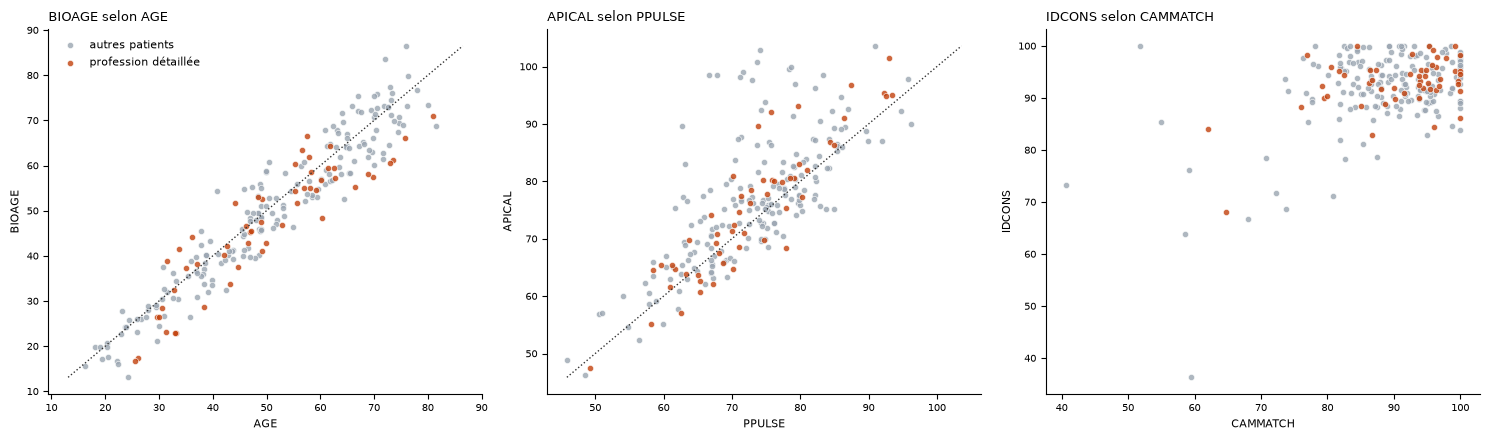

In [8]:
detail = P.set_index("patient_number")["occupation_detaillee"].reindex(patient.index)
couples = [("AGE", "BIOAGE", True), ("PPULSE", "APICAL", True), ("CAMMATCH", "IDCONS", False)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (x, y, diagonale) in zip(axes, couples):
    for grp, couleur, label in [(False, "#9aa5b1", "autres patients"), (True, "#c2410c", "profession détaillée")]:
        m = detail == grp
        ax.scatter(patient.loc[m, x], patient.loc[m, y], s=20, color=couleur, alpha=.8, edgecolor="white", linewidth=.5, label=label)
    if diagonale:
        lim = [patient[[x, y]].min().min(), patient[[x, y]].max().max()]
        ax.plot(lim, lim, color="#333", linewidth=1, linestyle=":")
    ax.set_xlabel(x, fontsize=8); ax.set_ylabel(y, fontsize=8); ax.tick_params(labelsize=7)
    ax.set_title(f"{y} selon {x}", fontsize=9, loc="left")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

* Âge biologique / âge réel : relation linéaire, avec quelques patients nettement sous la diagonale.
* Pouls cœur / poignet : linéaire, mais une dizaine de patients ont un cœur qui bat 25 à 30 fois de plus par minute qu'au poignet.
* Caméra / identité : pas de tendance d'ensemble, seulement quelques patients isolés en bas à gauche.

### 1.9 Bilan

Deux pistes : l'acte `MRP-42` chez des dirigeants qui rajeunissent, et quelques patients aux mesures étranges (pouls, yeux, identité). Dans les deux cas, les liens viennent de peu de patients, c'est pour ça que Spearman et Pearson ne disent pas toujours la même chose. À ce stade, ce ne sont que des corrélations.

## Cours 2 : Ordonner et regrouper ses données

Objectif : voir si les patients atypiques ressortent tout seuls, sans qu'on dise aux algorithmes qui chercher.

### 2.1 Choix des variables et mise à l'échelle

On ne garde que les 27 mesures médicales. Les variables qui se répètent sont remplacées par leur écart : `ECART_AGE` remplace l'âge biologique, et `ECART_POULS` remplace le pouls au cœur. On laisse de côté les actes, la profession et les comptages d'anomalies : ils servent à interpréter les groupes, pas à les former, sinon on retrouverait forcément ce qu'on y a mis.

Les unités étant très différentes, on standardise chaque variable (moyenne 0, écart-type 1). On mesure ensuite la ressemblance entre patients par la distance euclidienne.

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

MEDICAL = ["PPULSE", "ECART_POULS", "RPULSE", "ECART_AGE", "BALANCE", "CARDOUT", "COGNITIVE", "INFLAM", "LATSWAY",
           "MOBILITY", "O2SAT", "THORPEAK", "THORVIB"] + [c for c in UNIQUES]
X = feat[MEDICAL].fillna(feat[MEDICAL].median())
Z = StandardScaler().fit_transform(X)
print(Z.shape)

(240, 27)


### 2.2 Réduction de dimensions (PCA)

In [10]:
pca = PCA().fit(Z)
print("variance expliquée cumulée :", np.cumsum(pca.explained_variance_ratio_)[:6].round(2))
axes_pca = pd.DataFrame(pca.components_[:2].T, index=MEDICAL, columns=["axe 1", "axe 2"])
display(pd.DataFrame({a: axes_pca[a].abs().sort_values(ascending=False).head(5).index for a in axes_pca}))

variance expliquée cumulée : [0.1  0.18 0.24 0.3  0.35 0.4 ]


,axe 1,axe 2
0,ECART_POULS,MOBILITY
1,IDCONS,WALKSPD
2,THORPEAK,CVRISK
3,THORVIB,INFLAM
4,CAMMATCH,DIABP


Les variables sont peu liées entre elles : il faut 6 axes pour expliquer 40 % des différences entre patients. Les deux premiers axes ont pourtant un sens clair :
* axe 1 : écart de pouls, cohérence d'identité, indices thoraciques, reconnaissance caméra. On y retrouve exactement les anomalies du cours 1, qui varient ensemble chez certains patients ;
* axe 2 : mobilité, vitesse de marche, risque cardiovasculaire, inflammation. C'est un axe « âge et forme physique » classique.

### 2.3 Regroupement : comparaison des méthodes

On teste k-means (2 à 8 groupes), la classification hiérarchique avec trois façons de mesurer la distance entre groupes (2 à 6 groupes), et DBSCAN avec plusieurs réglages. Le score de silhouette mesure si les groupes sont bien séparés : 1 pour une séparation parfaite, 0 pour des groupes qui se chevauchent.

In [11]:
tests = []
for k in range(2, 9):
    lab = KMeans(k, n_init=20, random_state=0).fit_predict(Z)
    tests.append(("k-means", f"k={k}", silhouette_score(Z, lab), np.bincount(lab).min()))
for lien in ["ward", "average", "complete"]:
    for k in range(2, 7):
        lab = AgglomerativeClustering(k, linkage=lien).fit_predict(Z)
        tests.append(("hiérarchique " + lien, f"k={k}", silhouette_score(Z, lab), np.bincount(lab).min()))
dist5 = np.sort(NearestNeighbors(n_neighbors=5).fit(Z).kneighbors(Z)[0][:, -1])
for q in [.75, .9, .95]:
    for ms in [3, 5]:
        lab = DBSCAN(eps=np.quantile(dist5, q), min_samples=ms).fit_predict(Z)
        tests.append(("DBSCAN", f"eps={np.quantile(dist5, q):.1f}, min={ms}", np.nan, (lab == -1).sum()))
tests = pd.DataFrame(tests, columns=["méthode", "réglage", "silhouette", "plus petit groupe / nb hors groupe"])
display(tests.sort_values("silhouette", ascending=False).head(8).round(3))
display(tests[tests["méthode"] == "DBSCAN"])

,méthode,réglage,silhouette,plus petit groupe / nb hors groupe
12,hiérarchique average,k=2,0.242,13
7,hiérarchique ward,k=2,0.240,12
17,hiérarchique complete,k=2,0.240,12
0,k-means,k=2,0.220,20
13,hiérarchique average,k=3,0.190,1
14,hiérarchique average,k=4,0.166,1
15,hiérarchique average,k=5,0.148,1
16,hiérarchique average,k=6,0.140,1


,méthode,réglage,silhouette,plus petit groupe / nb hors groupe
22,DBSCAN,"eps=5.5, min=3",NaN,28
23,DBSCAN,"eps=5.5, min=5",NaN,31
24,DBSCAN,"eps=6.0, min=3",NaN,12
25,DBSCAN,"eps=6.0, min=5",NaN,15
26,DBSCAN,"eps=6.5, min=3",NaN,6
27,DBSCAN,"eps=6.5, min=5",NaN,6


Les silhouettes sont faibles (0,24 au mieux) : la plupart des patients forment un seul grand nuage, sans sous-groupes naturels. Les meilleurs découpages sont tous à 2 groupes, et ils isolent chaque fois un petit groupe d'une douzaine de patients. DBSCAN, lui, met une quinzaine de patients hors groupe. On garde la classification hiérarchique « average » à 2 groupes, et le DBSCAN au 90e percentile, pour voir qui sont ces patients.

In [12]:
groupes = pd.Series(AgglomerativeClustering(2, linkage="average").fit_predict(Z), index=feat.index)
hors_groupe = pd.Series(DBSCAN(eps=np.quantile(dist5, .9), min_samples=5).fit_predict(Z) == -1, index=feat.index)
petit = groupes[groupes != groupes.value_counts().idxmax()].index

occ = P.set_index("patient_number")["occupation_text"]
display(feat.loc[petit, ["ECART_POULS", "THORPEAK", "LATSWAY", "IDCONS", "CAMMATCH", "N_DISCORDANT", "N_OCULAR_ATYP", "NB_MRP42"]]
        .round(1).assign(groupe=groupes[petit], hors_groupe_DBSCAN=hors_groupe[petit], profession=occ[petit])
        .sort_values("ECART_POULS", ascending=False))
print("Patients hors groupe pour DBSCAN :", hors_groupe.sum(), "dont", hors_groupe[petit].sum(), "dans le petit groupe hiérarchique")
print("Hors groupe DBSCAN mais pas dans le petit groupe :", list(occ[hors_groupe[~hors_groupe.index.isin(petit)].pipe(lambda s: s[s]).index]))

,ECART_POULS,THORPEAK,LATSWAY,IDCONS,CAMMATCH,N_DISCORDANT,N_OCULAR_ATYP,NB_MRP42,groupe,hors_groupe_DBSCAN,profession
patient_number,,,,,,,,,,,
PAT-31209,32.0,74.7,45.2,86.8,93.5,5.0,0.0,0.0,1,False,administrative employee
PAT-31065,29.8,55.5,58.0,91.3,74.1,6.0,5.0,0.0,1,True,clinical specialist
PAT-31101,28.1,51.4,73.9,88.5,87.2,6.0,0.0,0.0,1,False,transport worker
PAT-31086,27.2,80.7,54.8,76.2,59.2,6.0,0.0,0.0,1,True,corporate adviser
PAT-31037,27.0,44.6,74.2,66.7,68.0,5.0,4.0,0.0,1,True,research professional
PAT-31215,26.3,55.1,67.6,78.2,82.6,6.0,0.0,0.0,1,True,research professional
PAT-31186,24.1,65.9,50.3,96.7,81.9,5.0,4.0,0.0,1,True,corporate adviser
PAT-31233,21.3,41.9,63.9,36.3,59.5,4.0,3.0,0.0,1,True,research professional
PAT-31040,19.9,59.9,77.2,71.1,80.8,5.0,0.0,0.0,1,True,research professional


Patients hors groupe pour DBSCAN : 15 dont 10 dans le petit groupe hiérarchique
Hors groupe DBSCAN mais pas dans le petit groupe : ['teacher', 'Senior executive-office official', 'retired professional', 'small-business owner', 'transport worker']


Le petit groupe contient 13 patients, dont 10 ont le même profil : grand écart de pouls, pic thoracique et balancement élevés, identité ou caméra souvent basses, et de nombreux pouls « discordants » ou suivis oculaires atypiques (qui ne servaient pas au regroupement). Ce sont les 10 professions discrètes repérées au cours 1 : 5 `research professional`, 3 `corporate adviser`, 2 `clinical specialist`. DBSCAN classe aussi ces 10 patients hors groupe. Les 3 autres sont des patients ordinaires avec une seule anomalie forte, sans doute des cas témoins.

Aucun des 8 dirigeants traités par `MRP-42` n'est dans ce groupe : sur les mesures médicales, ils ressemblent à tout le monde, sauf pour l'âge.

### 2.4 Visualisation : PCA et t-SNE

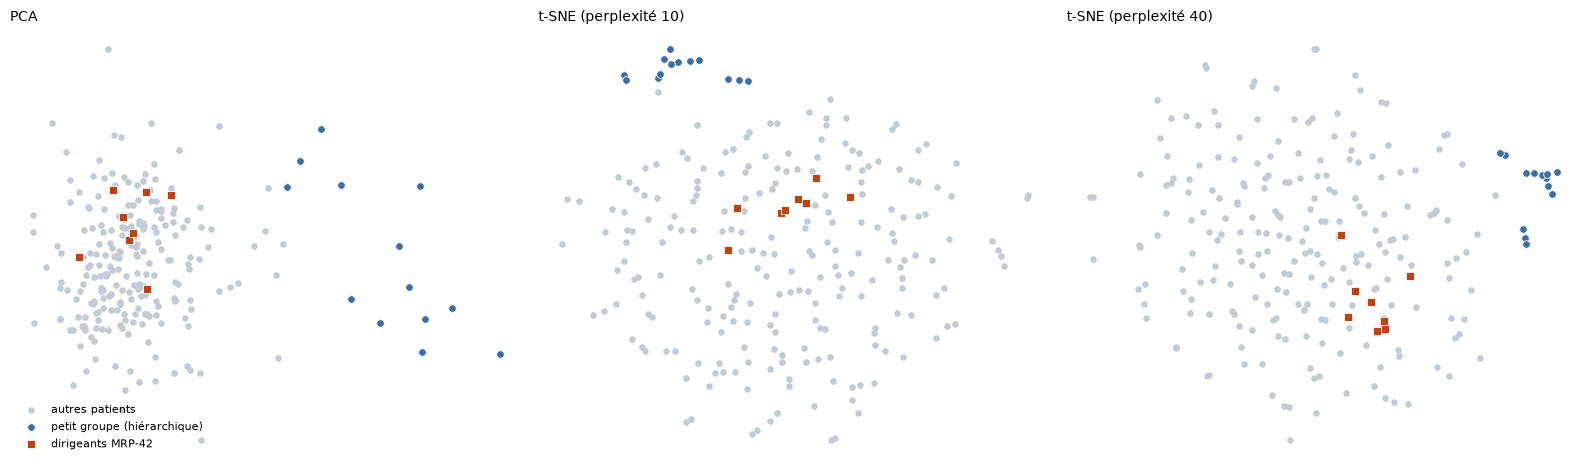

In [13]:
pc = PCA(2).fit_transform(Z)
cartes = {"PCA": pc} | {f"t-SNE (perplexité {p})": TSNE(perplexity=p, random_state=0).fit_transform(Z) for p in [10, 40]}
elite = feat["NB_MRP42"] >= 3
atyp = groupes.isin(groupes[petit].unique()) & ~elite

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (titre, xy) in zip(axes, cartes.items()):
    ax.scatter(*xy[~atyp & ~elite].T, s=14, color="#c3cbd4", label="autres patients")
    ax.scatter(*xy[atyp].T, s=30, color="#3b6ea5", edgecolor="white", linewidth=.6, label="petit groupe (hiérarchique)")
    ax.scatter(*xy[elite].T, s=40, marker="s", color="#c2410c", edgecolor="white", linewidth=.6, label="dirigeants MRP-42")
    ax.set_title(titre, fontsize=10, loc="left"); ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)
axes[0].legend(fontsize=8, frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

Sur les trois cartes, le petit groupe (en bleu) est à l'écart du nuage principal. Les dirigeants (en orange) sont au contraire mélangés aux autres patients. Le t-SNE sépare mieux que la PCA, comme l'annonce le cours, et le résultat reste le même avec deux réglages de perplexité différents.

### 2.5 Un second regroupement : le vieillissement

Les dirigeants ne se distinguent que par leur âge biologique, qui ne pèse qu'une variable sur 27. On refait donc un regroupement sur les seules variables de vieillissement : écart d'âge, vitesse de vieillissement (pente) et plus forte chute de l'écart d'âge entre deux visites.

In [14]:
AGE_VARS = ["ECART_AGE", "BIOAGE_PENTE", "CHUTE_MAX_AGE"]
Z_age = StandardScaler().fit_transform(feat[AGE_VARS].fillna(feat[AGE_VARS].median()))
for k in range(2, 6):
    print(f"k={k} silhouette={silhouette_score(Z_age, KMeans(k, n_init=20, random_state=0).fit_predict(Z_age)):.2f}")

g_age = pd.Series(KMeans(2, n_init=20, random_state=0).fit_predict(Z_age), index=feat.index)
rajeunis = g_age[g_age == g_age.value_counts().idxmin()].index
display(feat.loc[rajeunis, AGE_VARS + ["NB_MRP42"]].round(1).assign(profession=occ[rajeunis]).sort_values("NB_MRP42", ascending=False))

k=2 silhouette=0.79
k=3 silhouette=0.54
k=4 silhouette=0.53
k=5 silhouette=0.53


,ECART_AGE,BIOAGE_PENTE,CHUTE_MAX_AGE,NB_MRP42,profession
patient_number,,,,,
PAT-31221,-10.6,0.2,-6.5,5.0,Head of government of Kintara Republic
PAT-31174,-11.4,-0.2,-3.7,4.0,Regional governor in the Tembara Commonwealth
PAT-31044,-12.5,0.3,-4.4,4.0,Senior minister of the Avelora Federation
PAT-31119,-14.1,-0.9,-6.2,4.0,Chief executive of Solvane Energy Group
PAT-31074,-12.4,-0.9,-5.0,4.0,Executive chair of Nivren Maritime Logistics
PAT-31099,-8.9,-1.0,-5.3,3.0,Retired political intermediary and former coun...
PAT-31142,-10.9,-0.9,-5.7,3.0,Chair of Belen Agro-Industries
PAT-31183,-12.0,-0.9,-5.1,3.0,Executive director of Ardena Capital Union
PAT-31011,-7.0,-0.5,-10.9,1.0,transport worker


Avec 2 groupes, la séparation est très nette (silhouette 0,79). Le petit groupe compte 17 patients rajeunis :
* les 8 dirigeants traités par `MRP-42` ;
* 9 patients sans traitement répété enregistré (coordinateur de recherche, haut fonctionnaire, cadre régional, enseignant, commerçant…), qui ont pourtant un profil proche : écart d'âge de −7 à −12 ans et, pour la plupart, une chute brutale de 5 à 11 ans d'une visite à l'autre.

C'est incohérent : ces 9 patients semblent avoir reçu le même traitement, mais il n'apparaît pas dans leurs actes. Il pourrait s'agir de traitements non déclarés. On vérifiera dans les cours suivants (anomalies, chronologie) et en croisant avec les autres dossiers.

### 2.6 Bilan

Deux petits groupes sortent sans qu'on les ait désignés : 10 patients au profil physique atypique, et 17 patients rajeunis dont seulement 8 ont des injections enregistrées. Les deux groupes ne se recoupent pas.

## Cours 3 : Repérer des patterns et détecter des anomalies

On garde les trois groupes trouvés au cours 2 pour interpréter les résultats :
* ELITE : les 8 dirigeants traités par `MRP-42` de façon répétée ;
* PHENO : les 10 patients au profil physique atypique (petit groupe hiérarchique et hors groupe pour DBSCAN) ;
* RAJEUNI_NON_DECLARE : les 9 patients rajeunis sans traitement répété enregistré.

In [15]:
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

elite_ids = feat.index[feat["NB_MRP42"] >= 3]
pheno_ids = hors_groupe[petit][lambda s: s].index
grp = pd.Series("autre", index=feat.index)
grp[pheno_ids] = "PHENO"
grp[rajeunis.difference(elite_ids)] = "RAJEUNI_NON_DECLARE"
grp[elite_ids] = "ELITE"
grp.value_counts()

autre                  213
PHENO                   10
RAJEUNI_NON_DECLARE      9
ELITE                    8
Name: count, dtype: int64

### 3.1 Patterns : itemsets fréquents et règles d'association

Chaque patient devient une « transaction » qui contient des items vrais ou faux :
* des anomalies, obtenues en discrétisant les mesures comme le propose le cours (par exemple `idcons_bas` = 10 % des valeurs les plus basses) ;
* sa profession, sa clinique, les médecins qui l'ont vu, les actes et les types de consultation.

L'algorithme Apriori cherche les combinaisons fréquentes, puis on en tire des règles « si X alors Y ». Une règle est intéressante si sa confiance est élevée (Y est presque toujours présent quand X l'est) et si son lift est bien supérieur à 1 (X rend Y beaucoup plus probable qu'au hasard).

In [16]:
T = pd.DataFrame(index=feat.index)
for o in ["research professional", "corporate adviser", "clinical specialist"]:
    T["profession=" + o] = occ.reindex(feat.index).eq(o)
T["profession_detaillee"] = P.set_index("patient_number")["occupation_detaillee"].reindex(feat.index)
for fac in E["facility_license_number"].unique():
    T["vu_a_" + fac] = E[E["facility_license_number"] == fac].groupby("patient_number").size().reindex(feat.index).fillna(0) > 0
for lic in E["attending_license_number"].unique():
    T["medecin_" + lic[-8:]] = E[E["attending_license_number"] == lic].groupby("patient_number").size().reindex(feat.index).fillna(0) > 0
T["executive_review"] = feat["CONSULT_executive_health_review"] > 0
T["MRP42_repete"] = feat["NB_MRP42"] >= 3
T["MRP42_une_dose"] = feat["NB_MRP42"] == 1
T["age_bio_jeune"] = feat["ECART_AGE"] < -6
T["chute_age_brutale"] = feat["CHUTE_MAX_AGE"] < -4
T["pouls_discordant"] = feat["N_DISCORDANT"] >= 2
T["ocular_atypique"] = feat["N_OCULAR_ATYP"] >= 1
T["binocoord_atypique"] = feat["BINOCOORD_ATYP"] > 0
T["vestib_anormal"] = feat["VESTIB_ANORMAL"] > 0
for c, sens in [("LATSWAY", "haut"), ("THORPEAK", "haut"), ("IDCONS", "bas"), ("CAMMATCH", "bas"), ("THERMQUAL", "bas")]:
    q = feat[c].quantile(.9 if sens == "haut" else .1)
    T[f"{c.lower()}_{sens}"] = feat[c] > q if sens == "haut" else feat[c] < q
T = T.fillna(False).astype(bool)

frequents = apriori(T, min_support=0.02, use_colnames=True, max_len=4)
regles = association_rules(frequents, metric="lift", min_threshold=2)
regles = regles[(regles["confidence"] >= .8) & (regles["consequents"].apply(len) == 1)]
regles["si"] = regles["antecedents"].apply(lambda s: " + ".join(sorted(s)))
regles["alors"] = regles["consequents"].apply(lambda s: next(iter(s)))
print(f"{T.shape[1]} items, {len(frequents)} itemsets fréquents, {len(regles)} règles (confiance ≥ 0.8, lift ≥ 2)")

def meilleures(alors, n=4):
    r = regles[(regles["alors"] == alors) & (regles["antecedents"].apply(len) <= 2)]
    return r.sort_values(["confidence", "support", "lift"], ascending=False).head(n)

colonnes = ["si", "alors", "support", "confidence", "lift", "leverage"]
display(pd.concat([meilleures(a) for a in ["pouls_discordant", "age_bio_jeune", "MRP42_repete", "chute_age_brutale"]])[colonnes].round(3))

29 items, 1361 itemsets fréquents, 603 règles (confiance ≥ 0.8, lift ≥ 2)


,si,alors,support,confidence,lift,leverage
1027,idcons_bas + thorpeak_haut,pouls_discordant,0.033,1.000,9.600,0.030
973,binocoord_atypique + latsway_haut,pouls_discordant,0.029,1.000,9.600,0.026
979,binocoord_atypique + thorpeak_haut,pouls_discordant,0.029,1.000,9.600,0.026
985,binocoord_atypique + idcons_bas,pouls_discordant,0.029,1.000,9.600,0.026
21,executive_review,age_bio_jeune,0.083,1.000,5.714,0.069
671,executive_review + medecin_MED-1002,age_bio_jeune,0.071,1.000,5.714,0.058
28,chute_age_brutale,age_bio_jeune,0.058,1.000,5.714,0.048
925,chute_age_brutale + executive_review,age_bio_jeune,0.058,1.000,5.714,0.048
845,executive_review + medecin_RES-1044,chute_age_brutale,0.033,0.889,15.238,0.031
27,MRP42_repete,chute_age_brutale,0.029,0.875,15.000,0.027


Les règles les plus fortes décrivent deux « recettes » :
* profil atypique : quand deux anomalies sont présentes ensemble (identité basse et pic thoracique, ou coordination des yeux atypique et balancement…), le pouls est toujours discordant. Confiance 100 %, lift 9,6 : c'est près de 10 fois plus que le hasard ;
* rajeunissement : tous les patients qui ont des « executive health reviews » ont un âge biologique jeune (confiance 100 %, lift 5,7). Le traitement `MRP-42` répété entraîne une chute brutale dans 7 cas sur 8 (lift 15).

### 3.2 Co-occurrences : qui administre `MRP-42` ?

Le cours recommande d'exprimer une matrice de co-occurrence en pourcentages par ligne.

In [17]:
mrp_actes = PR[PR["procedure_code"] == "MRP-42"].assign(groupe=lambda d: d["patient_number"].map(grp))
display((pd.crosstab(mrp_actes["performing_license_number"], mrp_actes["groupe"], normalize="index") * 100).round(0)
        .assign(nb_actes=mrp_actes["performing_license_number"].value_counts()))
E["groupe"] = E["patient_number"].map(grp)
display((pd.crosstab(E["groupe"], E["encounter_type"], normalize="index") * 100).round(0)
        [["executive_health_review", "specialist_procedure", "cardiac_assessment", "ocular_assessment", "mobility_assessment"]])

groupe,ELITE,RAJEUNI_NON_DECLARE,autre,nb_actes
performing_license_number,,,,
LIC-VLN-MED-1001,0.0,0.0,100.0,1
LIC-VLN-MED-1002,83.0,3.0,14.0,36
LIC-VLN-MED-1003,0.0,0.0,100.0,1
LIC-VLN-MED-1004,0.0,0.0,100.0,3
LIC-VLN-MED-1006,0.0,0.0,100.0,4
LIC-VLN-RES-1016,0.0,0.0,100.0,3
LIC-VLN-RES-1044,0.0,0.0,100.0,2


encounter_type,executive_health_review,specialist_procedure,cardiac_assessment,ocular_assessment,mobility_assessment
groupe,,,,,
ELITE,56.0,44.0,0.0,0.0,0.0
PHENO,0.0,0.0,29.0,22.0,36.0
RAJEUNI_NON_DECLARE,98.0,0.0,0.0,0.0,0.0
autre,2.0,0.0,7.0,4.0,7.0


* Le médecin `LIC-VLN-MED-1002` a réalisé les 30 doses données aux dirigeants. Les 6 autres `MRP-42` qu'il a faits sont des doses uniques « recherche ».
* Les rajeunis non déclarés n'ont que des « executive health reviews » (98 % de leurs consultations), exactement comme les dirigeants. Mais ils n'ont aucune consultation « procédure » enregistrée, alors que c'est lors de ces consultations que les dirigeants reçoivent leurs doses.
* Le groupe PHENO n'a que des bilans cardiaques, oculaires et de mobilité : il est suivi de près pour ses anomalies.

### 3.3 Anomalies univariées : IQR, z-score, z-score modifié

On compare les trois méthodes du cours sur les 27 mesures médicales par patient.

In [18]:
Xm = feat[MEDICAL]
q1, q3 = Xm.quantile(.25), Xm.quantile(.75)
methodes = {
    "IQR": (Xm < q1 - 1.5 * (q3 - q1)) | (Xm > q3 + 1.5 * (q3 - q1)),
    "z-score > 3": ((Xm - Xm.mean()) / Xm.std()).abs() > 3,
    "z modifié > 3.5": (0.6745 * (Xm - Xm.median()) / (Xm - Xm.median()).abs().median()).abs() > 3.5,
}
display(pd.DataFrame({m: {"valeurs aberrantes": a.sum().sum(), **a.sum(axis=1).groupby(grp).mean().round(2).to_dict()}
                      for m, a in methodes.items()}))

,IQR,z-score > 3,z modifié > 3.5
valeurs aberrantes,140.00,46.00,46.00
ELITE,0.12,0.00,0.00
PHENO,4.00,1.60,1.90
RAJEUNI_NON_DECLARE,0.11,0.00,0.00
autre,0.46,0.14,0.13


L'IQR signale 3 fois plus de valeurs que les z-scores, car il est plus sensible aux distributions étirées. Quelle que soit la méthode, le groupe PHENO concentre les valeurs aberrantes (2 à 4 par patient, contre 0,1 à 0,5 pour les autres). Les dirigeants et les rajeunis n'en ont presque aucune : leur particularité n'est pas une valeur extrême, mais un changement dans le temps.

### 3.4 Anomalies par rapport à l'historique du patient

C'est l'exemple du cours sur les retraits bancaires : une valeur peut être normale pour la population mais anormale pour cette personne. On compare donc chaque visite à l'historique du même patient, avec un z-score modifié (médiane et écart absolu médian du patient).

In [19]:
lignes = []
for pid, d in W2.groupby("patient_number"):
    s = d.set_index("encounter_number")["ECART_AGE"].dropna()
    if len(s) < 4:
        continue
    ecart_abs = max((s - s.median()).abs().median(), 0.5)
    zmod = 0.6745 * (s - s.median()) / ecart_abs
    for enc, z in zmod[zmod.abs() > 6].items():
        lignes.append((pid, enc, s[enc], s.median(), z))
ruptures = pd.DataFrame(lignes, columns=["patient", "consultation", "écart âge", "médiane du patient", "z modifié"])
ruptures = ruptures.assign(date=ruptures["consultation"].map(E.set_index("encounter_number")["encounter_start"]),
                           type=ruptures["consultation"].map(E.set_index("encounter_number")["encounter_type"]),
                           groupe=ruptures["patient"].map(grp))
ruptures.sort_values("z modifié").round({"écart âge": 1, "médiane du patient": 1, "z modifié": 1})

,patient,consultation,écart âge,médiane du patient,z modifié,date,type,groupe
0,PAT-31011,ENC-000780,-17.8,-7.0,-14.7,2021-05-01 13:15:00,executive_health_review,RAJEUNI_NON_DECLARE
5,PAT-31122,ENC-000448,-19.1,-8.8,-13.8,2024-08-03 13:15:00,executive_health_review,RAJEUNI_NON_DECLARE
2,PAT-31046,ENC-000347,-18.0,-8.5,-12.8,2025-06-20 13:15:00,executive_health_review,RAJEUNI_NON_DECLARE
4,PAT-31110,ENC-000694,-15.9,-6.7,-12.3,2020-05-22 13:15:00,executive_health_review,RAJEUNI_NON_DECLARE
1,PAT-31017,ENC-000162,-13.9,-7.3,-8.9,2025-06-20 13:15:00,executive_health_review,RAJEUNI_NON_DECLARE
6,PAT-31179,ENC-000264,-13.5,-8.7,-6.4,2022-12-16 13:15:00,executive_health_review,RAJEUNI_NON_DECLARE
3,PAT-31071,ENC-000232,-13.6,-9.2,-6.0,2024-02-23 13:15:00,executive_health_review,RAJEUNI_NON_DECLARE


Les ruptures les plus nettes (z modifié de −6 à −15) concernent les rajeunis non déclarés. Elles ont toutes lieu lors d'une « executive health review », et deux d'entre elles tombent le même jour, le 20 juin 2025.

### 3.5 Anomalies multivariées : Isolation Forest, LOF, ABOD

On applique les trois méthodes du cours aux 27 mesures standardisées, et on classe les patients selon leur rang moyen.

In [20]:
score_iso = -IsolationForest(n_estimators=500, random_state=0).fit(Z).score_samples(Z)
score_lof = -LocalOutlierFactor(n_neighbors=20).fit(Z).negative_outlier_factor_

def abod(Z):
    # variance des angles (pondérés par la distance) entre un point et toutes les paires d'autres points
    sortie = np.empty(len(Z))
    for i in range(len(Z)):
        V = np.delete(Z, i, axis=0) - Z[i]
        n2 = (V ** 2).sum(axis=1)
        M = (V @ V.T) / np.outer(n2, n2)
        sortie[i] = M[np.triu_indices(len(V), 1)].var()
    return sortie

score_abod = -np.log(abod(Z))   # faible variance d'angles = point isolé (log pour un score lisible)
scores = pd.DataFrame({"Isolation Forest": score_iso, "LOF": score_lof, "ABOD": score_abod}, index=feat.index)
scores["rang moyen"] = scores.rank(ascending=False).mean(axis=1)
top = scores.sort_values("rang moyen").head(15)
display(top.round(3).assign(groupe=grp[top.index], profession=occ[top.index],
                            IDCONS=feat.loc[top.index, "IDCONS"], CAMMATCH=feat.loc[top.index, "CAMMATCH"]))
print({m: grp[scores[m].nlargest(15).index].value_counts().to_dict() for m in ["Isolation Forest", "LOF", "ABOD"]})

,Isolation Forest,LOF,ABOD,rang moyen,groupe,profession,IDCONS,CAMMATCH
patient_number,,,,,,,,
PAT-31233,0.524,1.459,14.544,2.333,PHENO,research professional,36.3,59.5
PAT-31186,0.534,1.318,12.972,4.333,PHENO,corporate adviser,96.7,81.9
PAT-31086,0.531,1.246,13.299,4.667,PHENO,corporate adviser,76.2,59.2
PAT-31065,0.534,1.241,13.130,5.667,PHENO,clinical specialist,91.3,74.1
PAT-31139,0.502,1.383,13.074,5.667,autre,retired professional,73.2,40.6
PAT-31037,0.517,1.258,13.269,6.000,PHENO,research professional,66.7,68.0
PAT-31181,0.519,1.343,12.770,6.333,autre,transport worker,97.1,100.0
PAT-31152,0.525,1.334,12.719,6.333,autre,small-business owner,100.0,78.1
PAT-31162,0.518,1.244,12.893,8.000,PHENO,corporate adviser,68.6,73.7


{'Isolation Forest': {'PHENO': 8, 'autre': 7}, 'LOF': {'PHENO': 8, 'autre': 7}, 'ABOD': {'PHENO': 9, 'autre': 6}}


Les trois méthodes placent 8 ou 9 patients PHENO dans leurs 15 premiers. Elles font aussi ressortir quelques patients ordinaires que les étapes précédentes n'avaient pas isolés :
* certains ont une reconnaissance caméra ou une cohérence d'identité très basses sans aucune autre anomalie. Par exemple `PAT-31139` (caméra 40,6, la plus basse de tous) et `PAT-31031` (identité 63,8). La personne mesurée est-elle bien la bonne ?
* d'autres ont une seule anomalie forte (test vestibulaire anormal, pouls discordant isolé). Ce sont probablement les cas témoins évoqués dans les notes cliniques.

### 3.6 Un événement anormal : le 20 juin 2025

In [21]:
E["jour"] = E["encounter_start"].dt.date.astype(str)
print("Jours avec le plus de consultations :", E["jour"].value_counts().head(3).to_dict())

chevauchements = []
for medecin, d in E.sort_values("encounter_start").groupby("attending_license_number"):
    d = d.reset_index(drop=True)
    for i in range(len(d)):
        for j in range(i + 1, len(d)):
            if d.loc[j, "encounter_start"] >= d.loc[i, "encounter_end"]:
                break
            chevauchements.append((medecin, d.loc[i, "jour"], d.loc[i, "facility_license_number"] != d.loc[j, "facility_license_number"]))
chev = pd.DataFrame(chevauchements, columns=["médecin", "jour", "deux cliniques à la fois"])
display(chev.groupby("jour").agg(consultations_simultanées=("médecin", "size"), dans_deux_cliniques=("deux cliniques à la fois", "sum"))
        .sort_values("consultations_simultanées", ascending=False).head(3))

j20 = E[E["jour"] == "2025-06-20"]
print("Consultations du 20/06/2025 :", len(j20), "| dont à 13h15 :", (j20["encounter_start"].dt.strftime("%H:%M") == "13:15").sum(),
      "| programmées à l'avance comme suivi :", pd.to_datetime(E["follow_up_date"]).dt.date.astype(str).eq("2025-06-20").sum())
display(j20.groupby("attending_license_number")["facility_license_number"].agg(lambda s: dict(s.value_counts())).rename("cliniques"))

Jours avec le plus de consultations : {'2025-06-20': 22, '2019-09-04': 3, '2021-07-18': 3}


,consultations_simultanées,dans_deux_cliniques
jour,,
2025-06-20,25,11
2023-06-17,3,2
2018-07-21,1,1


Consultations du 20/06/2025 : 22 | dont à 13h15 : 17 | programmées à l'avance comme suivi : 22


attending_license_number
LIC-VLN-MED-1001                 {'FAC-AVL-301': 1, 'FAC-VLN-101': 1}
LIC-VLN-MED-1002                 {'FAC-VLN-101': 5, 'FAC-AVL-201': 1}
LIC-VLN-MED-1004    {'FAC-AVL-301': 1, 'FAC-AVL-201': 1, 'FAC-VLN-...
LIC-VLN-MED-1005                                   {'FAC-VLN-101': 2}
LIC-VLN-MED-1006                                   {'FAC-VLN-101': 2}
LIC-VLN-RES-1016                 {'FAC-VLN-101': 3, 'FAC-AVL-301': 1}
LIC-VLN-RES-1044                 {'FAC-AVL-201': 2, 'FAC-VLN-101': 1}
Name: cliniques, dtype: object

Le 20 juin 2025 ne ressemble à aucun autre jour :
* 22 consultations, alors qu'aucun autre jour n'en compte plus de 3. Elles ont toutes été fixées des mois à l'avance comme date de suivi ;
* elles se déroulent toutes au même moment. L'heure en elle-même ne veut rien dire : dans ces données, elle dépend seulement du rang de la visite (1re visite à 9h15, 2e à 10h15…), ce qui est un artefact de génération. Ce qui est anormal, c'est que toutes ces visites tombent le même jour ;
* les médecins sont dans plusieurs consultations en même temps, parfois dans deux cliniques de deux pays différents (Valenne et Avelora). Un médecin ne peut pas être dans deux pays en même temps.

Ces consultations ne peuvent pas être réelles : soit elles ont été saisies en masse ou inventées, soit elles cachent un événement particulier. Deux rajeunis non déclarés y subissent leur chute d'âge biologique. Cette date est à rechercher dans les autres dossiers lors de la mise en commun.

### 3.7 Bilan

Les règles d'association et les anomalies redisent les deux profils. Ce qui est nouveau : les rajeunis non déclarés ont le même parcours que les dirigeants sans l'acte, et le 20 juin 2025 ne peut pas correspondre à de vraies consultations.

## Cours 4 : Miner des graphes et des processus

### 4.1 Le réseau patients – médecins

On construit un graphe biparti : les nœuds sont les patients et les médecins, et un lien relie un patient à un médecin qui l'a reçu, pondéré par le nombre de consultations. On le décrit d'abord avec les mesures du cours.

In [22]:
import networkx as nx
from networkx.algorithms import community as nxc

B = nx.Graph()
for (p_, m_), w in E.groupby(["patient_number", "attending_license_number"]).size().items():
    B.add_edge(p_, m_, weight=w)
medecins = sorted(E["attending_license_number"].unique())
print(f"N = {B.number_of_nodes()} nœuds ({len(medecins)} médecins), L = {B.number_of_edges()} liens, "
      f"densité biparti = {B.number_of_edges() / (len(medecins) * (B.number_of_nodes() - len(medecins))):.2f}")

E["restreinte"] = E["confidentiality_class"] == "restricted"
display(pd.DataFrame({
    "degré (patients)": {m_: B.degree(m_) for m_ in medecins},
    "force (consultations)": {m_: B.degree(m_, weight="weight") for m_ in medecins},
    "% consultations restreintes": E.groupby("attending_license_number")["restreinte"].mean().mul(100).round(0),
    "consultations de dirigeants": E[E["groupe"] == "ELITE"].groupby("attending_license_number").size(),
}).fillna(0))

N = 248 nœuds (8 médecins), L = 844 liens, densité biparti = 0.44


,degré (patients),force (consultations),% consultations restreintes,consultations de dirigeants
LIC-VLN-MED-1001,118,147,22.0,12
LIC-VLN-MED-1002,112,162,39.0,33
LIC-VLN-MED-1003,99,121,9.0,5
LIC-VLN-MED-1004,98,121,11.0,6
LIC-VLN-MED-1005,96,119,16.0,4
LIC-VLN-MED-1006,110,136,14.0,3
LIC-VLN-RES-1016,112,140,14.0,1
LIC-VLN-RES-1044,99,121,11.0,4


Les 8 médecins ont tous un degré proche (96 à 118 patients chacun) : vu de loin, chaque médecin voit un peu tout le monde. Seule différence nette : `MED-1002` a 33 consultations de dirigeants, contre 1 à 12 pour les autres, et 39 % de ses consultations sont restreintes.

Pour aller plus loin, on relie deux patients quand ils sont suivis par les mêmes médecins dans les mêmes proportions (similarité de leurs profils de médecins, en ne gardant que les 5 % de paires les plus proches). On cherche ensuite des communautés avec l'algorithme de Louvain. On le relance avec plusieurs seuils et plusieurs initialisations pour vérifier que le résultat est stable.

In [23]:
profil_med = E.groupby(["patient_number", "attending_license_number"]).size().unstack(fill_value=0)
profil_med = profil_med.div(profil_med.sum(axis=1), axis=0)
simil = (profil_med @ profil_med.T).to_numpy(copy=True)
np.fill_diagonal(simil, 0)

def graphe_patients(q):
    seuil = np.quantile(simil[np.triu_indices(len(simil), 1)], q)
    G = nx.Graph()
    G.add_nodes_from(profil_med.index)
    ii, jj = np.where(np.triu(simil > seuil, 1))
    G.add_weighted_edges_from((profil_med.index[i], profil_med.index[j], simil[i, j]) for i, j in zip(ii, jj))
    return G

G = graphe_patients(.95)
print(f"Graphe patients : N = {G.number_of_nodes()}, L = {G.number_of_edges()}, densité = {nx.density(G):.3f}, "
      f"coefficient de regroupement moyen = {nx.average_clustering(G):.2f}")

stabilite = []
for q in [.9, .95, .98]:
    Gq = graphe_patients(q)
    for graine in [0, 1, 2]:
        comms = nxc.louvain_communities(Gq, weight="weight", seed=graine)
        c_elite = [c for c in comms if set(elite_ids) & c]
        stabilite.append({"seuil": q, "graine": graine, "communautés": len(comms),
                          "modularité": round(nxc.modularity(Gq, comms, weight="weight"), 2),
                          "communautés contenant des dirigeants": len(c_elite),
                          "taille": len(c_elite[0]), "dirigeants dedans": len(set(elite_ids) & c_elite[0]),
                          "médecin dominant": profil_med.loc[list(c_elite[0])].mean().idxmax(),
                          "communautés des 9 rajeunis non déclarés": len([c for c in comms if set(grp[grp == "RAJEUNI_NON_DECLARE"].index) & c])})
display(pd.DataFrame(stabilite))

Graphe patients : N = 240, L = 1304, densité = 0.045, coefficient de regroupement moyen = 0.42


,seuil,graine,communautés,modularité,communautés contenant des dirigeants,taille,dirigeants dedans,médecin dominant,communautés des 9 rajeunis non déclarés
0,0.90,0,28,0.46,1,48,8,LIC-VLN-MED-1002,7
1,0.90,1,29,0.46,1,45,8,LIC-VLN-MED-1002,8
2,0.90,2,28,0.45,1,51,8,LIC-VLN-MED-1002,7
3,0.95,0,72,0.55,1,32,8,LIC-VLN-MED-1002,8
4,0.95,1,71,0.56,1,34,8,LIC-VLN-MED-1002,8
5,0.95,2,71,0.55,1,34,8,LIC-VLN-MED-1002,8
6,0.98,0,88,0.65,1,30,8,LIC-VLN-MED-1002,8
7,0.98,1,88,0.65,1,30,8,LIC-VLN-MED-1002,8
8,0.98,2,88,0.65,1,33,8,LIC-VLN-MED-1002,8


Dans les 9 essais, les 8 dirigeants sont toujours dans la même communauté, toujours organisée autour du médecin `MED-1002`. La modularité (0,45 à 0,65) indique une vraie structure en communautés. Les rajeunis non déclarés, eux, sont dispersés entre les communautés : ils ne passent pas par un médecin unique, ce qui rend leur traitement plus difficile à repérer.

### 4.2 Les nœuds importants

On ajoute au graphe les cliniques, les types de consultation et les types d'actes, puis on mesure l'importance de chaque patient : son degré, sa betweenness (à quel point il sert de « pont » entre des parties du réseau) et sa closeness (à quel point il est proche de tous les autres nœuds).

In [24]:
G4 = nx.Graph()
for r in E.itertuples():
    G4.add_edges_from([(r.patient_number, r.attending_license_number), (r.patient_number, r.facility_license_number),
                       (r.patient_number, "TYPE:" + r.encounter_type)])
for r in PR.itertuples():
    G4.add_edges_from([(r.patient_number, "ACTE:" + r.procedure_code), (r.performing_license_number, "ACTE:" + r.procedure_code)])
centr = pd.DataFrame({"degré": dict(G4.degree()), "betweenness": nx.betweenness_centrality(G4),
                      "closeness": nx.closeness_centrality(G4)})
centr = centr[centr.index.str.startswith("PAT")]
display(centr.groupby(grp).mean().round(4))

,degré,betweenness,closeness
ELITE,8.6250,0.0013,0.4925
PHENO,9.9000,0.0012,0.4992
RAJEUNI_NON_DECLARE,7.6667,0.0005,0.4918
autre,7.6573,0.0003,0.4927


Les dirigeants et les patients PHENO ont une betweenness environ 4 fois plus élevée que les autres patients. Ils sont reliés à des nœuds rares que presque personne d'autre ne touche : consultations « procédure », bilans oculaires ou cardiaques ciblés, clinique `FAC-AVL-301`. Ce sont donc des patients « à part » dans l'organisation des soins, pas seulement dans leurs mesures.

### 4.3 Process mining : le parcours des patients

On construit un journal d'événements : pour chaque patient, la suite chronologique de ses consultations (par type), de ses actes et de ses enregistrements cardiaques. Chaque patient forme une « trace ». On en tire le graphe des enchaînements directs (« A puis B »), groupe par groupe.

In [25]:
evenements = pd.concat([
    E[["patient_number", "encounter_start", "encounter_type"]].set_axis(["patient", "t", "etape"], axis=1),
    PR.assign(t=pd.to_datetime(PR["performed_time"]), etape="acte " + PR["procedure_code"])[["patient_number", "t", "etape"]].set_axis(["patient", "t", "etape"], axis=1),
    CR.assign(t=pd.to_datetime(CR["recording_date"]), etape="ECG " + CR["recording_context"])[["patient_number", "t", "etape"]].set_axis(["patient", "t", "etape"], axis=1),
]).sort_values(["patient", "t"])
traces = evenements.groupby("patient")["etape"].apply(lambda s: ("DEBUT",) + tuple(s) + ("FIN",))
print(f"{len(evenements)} événements, {traces.nunique()} parcours différents pour {len(traces)} patients")

def enchainements(liste_traces):
    c = Counter()
    for t in liste_traces:
        c.update(zip(t, t[1:]))
    return c

from collections import Counter
dfg = {g_: enchainements(traces[grp.reindex(traces.index) == g_]) for g_ in ["ELITE", "RAJEUNI_NON_DECLARE", "PHENO"]}
display(pd.DataFrame({g_: [f"{a} → {b} ({n})" for (a, b), n in c.most_common(5)] for g_, c in dfg.items()}))

1421 événements, 229 parcours différents pour 240 patients


,ELITE,RAJEUNI_NON_DECLARE,PHENO
0,specialist_procedure → acte MRP-42 (30),executive_health_review → executive_health_rev...,DEBUT → cardiac_assessment (5)
1,executive_health_review → specialist_procedure...,DEBUT → executive_health_review (9),cardiac_assessment → cardiac_assessment (4)
2,acte MRP-42 → executive_health_review (26),executive_health_review → acte AGE-PNL (4),mobility_assessment → mobility_assessment (4)
3,DEBUT → executive_health_review (8),executive_health_review → FIN (4),cardiac_assessment → mobility_assessment (3)
4,executive_health_review → FIN (8),acte AGE-PNL → executive_health_review (3),specialist_follow_up → mobility_assessment (3)


On applique aussi l'Heuristic Miner sur tout le journal. Il calcule pour chaque enchaînement A → B un degré de dépendance compris entre −1 et 1 : proche de 1, cela veut dire que « A est presque toujours suivi de B, et jamais l'inverse ».

In [26]:
tout = enchainements(traces)
dependance = pd.Series({(a, b): (n - tout[(b, a)]) / (n + tout[(b, a)] + 1) for (a, b), n in tout.items() if a != b})
dependance = dependance[~dependance.index.map(lambda x: x[0] == "DEBUT" or x[1] == "FIN")]
display(dependance.sort_values(ascending=False).head(6).round(2).rename("dépendance").to_frame())

ev_el = evenements[evenements["patient"].isin(elite_ids)].copy()
ev_el["délai suivant (jours)"] = ev_el.groupby("patient")["t"].shift(-1).sub(ev_el["t"]).dt.days
print("Délai entre une injection MRP-42 et l'étape suivante :",
      ev_el.loc[ev_el["etape"] == "acte MRP-42", "délai suivant (jours)"].describe()[["mean", "std", "min", "max"]].round(0).to_dict())

,,dépendance
specialist_procedure,acte MRP-42,0.97
acte MRP-42,executive_health_review,0.96
executive_health_review,specialist_procedure,0.96
research_procedure,acte MRP-42,0.95
general_examination,research_procedure,0.83
specialist_follow_up,research_procedure,0.83


Délai entre une injection MRP-42 et l'étape suivante : {'mean': 35.0, 'std': 6.0, 'min': 27.0, 'max': 43.0}


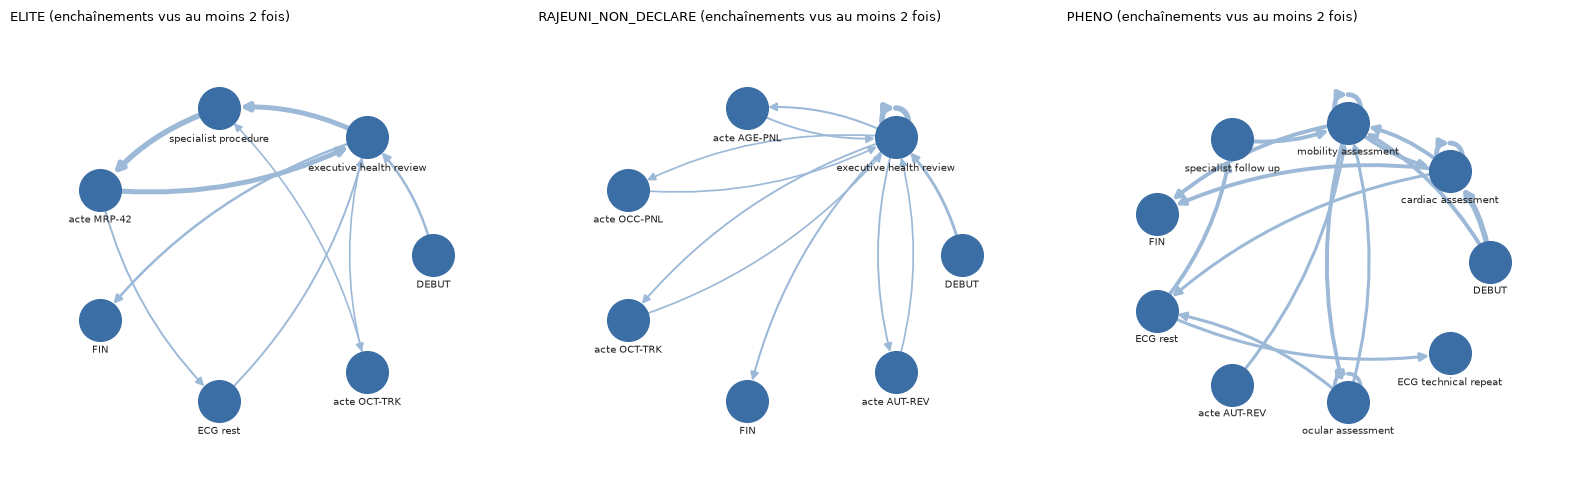

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (g_, c) in zip(axes, dfg.items()):
    H = nx.DiGraph()
    for (a, b), n in c.items():
        if n >= 2:
            H.add_edge(a, b, weight=n)
    pos = nx.circular_layout(H)
    poids = [H[u][v]["weight"] for u, v in H.edges()]
    nx.draw_networkx_edges(H, pos, ax=ax, width=[1 + 3 * w / max(poids) for w in poids], edge_color="#9db9d8",
                           arrows=True, arrowsize=12, connectionstyle="arc3,rad=0.15", node_size=900)
    nx.draw_networkx_nodes(H, pos, ax=ax, node_size=900, node_color="#3b6ea5")
    for n_, (x, y) in pos.items():
        ax.text(x, y - 0.17, n_.replace("_", " "), ha="center", va="top", fontsize=7, color="#222")
    ax.set_title(f"{g_} (enchaînements vus au moins 2 fois)", fontsize=9, loc="left")
    ax.axis("off"); ax.margins(0.2)
plt.tight_layout(); plt.show()

Les trois groupes ont des parcours très différents, et très différents de celui des patients ordinaires (examen général, suivi, bilan professionnel) :
* ELITE : un cycle parfaitement régulier. « Executive review », puis consultation « procédure », puis injection `MRP-42`, puis « executive review » environ 35 jours plus tard (écart-type de 6 jours). L'Heuristic Miner confirme ce cycle avec des dépendances de 0,96 à 0,97 ;
* RAJEUNI_NON_DECLARE : une simple boucle « executive review » → « executive review », sans étape de procédure. C'est le cycle des dirigeants sans l'injection, alors que l'effet (le rajeunissement) est le même ;
* PHENO : un va-et-vient entre bilans cardiaques, de mobilité et oculaires, avec des ECG répétés. C'est le parcours d'une surveillance spécialisée.

### 4.4 Traçabilité du produit : les numéros de lot

Chaque injection `MRP-42` porte une référence de matériel `MTL-année-numéro`. On classe les lots par numéro.

In [28]:
lots = PR[PR["procedure_code"] == "MRP-42"].copy()
lots["série"] = np.where(lots["material_reference"].str.startswith("MTL-R"), "recherche (MTL-R)", "dirigeants (MTL)")
lots["numéro"] = lots["material_reference"].str[-4:].astype(int)
blocs = (lots[lots["série"] == "dirigeants (MTL)"].groupby("patient_number")
         .agg(lots=("numéro", lambda s: f"{s.min()} à {s.max()}"), premier_lot=("numéro", "min"), première_injection=("performed_time", "min"))
         .sort_values("premier_lot").join(occ))
display(blocs)
print("Numéros utilisés :", lots.groupby("série")["numéro"].agg(["min", "max", "count"]).to_dict("index"))

,lots,premier_lot,première_injection,occupation_text
patient_number,,,,
PAT-31221,2 à 6,2,2016-02-18T09:05:00,Head of government of Kintara Republic
PAT-31044,7 à 10,7,2017-05-12T09:05:00,Senior minister of the Avelora Federation
PAT-31174,11 à 14,11,2015-09-10T09:05:00,Regional governor in the Tembara Commonwealth
PAT-31119,15 à 18,15,2018-01-26T09:05:00,Chief executive of Solvane Energy Group
PAT-31074,19 à 22,19,2017-11-03T09:05:00,Executive chair of Nivren Maritime Logistics
PAT-31183,23 à 25,23,2016-06-16T09:05:00,Executive director of Ardena Capital Union
PAT-31142,26 à 28,26,2019-03-14T09:05:00,Chair of Belen Agro-Industries
PAT-31099,29 à 31,29,2014-07-18T09:05:00,Retired political intermediary and former coun...


Numéros utilisés : {'dirigeants (MTL)': {'min': 2, 'max': 31, 'count': 30}, 'recherche (MTL-R)': {'min': 32, 'max': 51, 'count': 20}}


* Les numéros de lot 2 à 31 sont attribués par blocs consécutifs à chaque dirigeant, et dans l'ordre de la hiérarchie : chef de gouvernement (lots 2 à 6), ministre, gouverneur, puis les PDG, et l'ancien intermédiaire politique en dernier. Ce n'est pas l'ordre chronologique : l'ancien intermédiaire reçoit le lot 29 dès 2014, deux ans avant que le lot 2 ne soit utilisé. On peut penser que les doses ont été réservées à l'avance pour chaque dirigeant, mais ce n'est qu'une hypothèse.
* La série « recherche » (`MTL-R`) prend la suite (32 à 51) pour 20 patients ordinaires.
* Le lot n° 1 n'apparaît nulle part. Une dose a-t-elle été administrée sans être enregistrée, ou à quelqu'un qui n'est pas dans ce dossier ? C'est à chercher dans les commandes et livraisons du dossier `logistics`.

### 4.5 Bilan

Les dirigeants forment une communauté autour de `MED-1002` et suivent un cycle régulier. Les rajeunis non déclarés ont le même cycle, sans l'injection. Les lots ont été attribués dans l'ordre de la hiérarchie, et le lot n° 1 manque.

## Cours 5 : Miner des données spatiales et temporelles

### 5.1 Données spatiales

Le dossier health ne contient pas de coordonnées. On a seulement la région de chaque patient (5 régions) et le pays de chaque clinique, codé dans son identifiant (`VLN` = Valenne, `AVL` = Avelora). Avec 5 régions sans information de voisinage et 3 cliniques, l'I de Moran ou LISA n'auraient pas de sens. On regarde donc simplement si les groupes sont concentrés quelque part.

In [29]:
P_idx = P.set_index("patient_number")
display(pd.crosstab(P_idx["home_region"], grp.reindex(P_idx.index)))
display((pd.crosstab(E["groupe"], E["facility_license_number"], normalize="index") * 100).round(0))

col_0,ELITE,PHENO,RAJEUNI_NON_DECLARE,autre
home_region,,,,
Avelora Federation,2,2,4,46
Kintara Republic,2,1,1,43
Nordhaven Union,1,1,1,49
Tembara Commonwealth,1,1,1,36
Valenne Republic,2,5,2,39


facility_license_number,FAC-AVL-201,FAC-AVL-301,FAC-VLN-101
groupe,,,
ELITE,47.0,0.0,53.0
PHENO,29.0,31.0,40.0
RAJEUNI_NON_DECLARE,33.0,11.0,57.0
autre,26.0,10.0,64.0


* Les trois groupes viennent de toutes les régions. Aucune concentration géographique n'apparaît, donc une cause locale (environnement, exposition) est peu probable.
* Les patients PHENO passent beaucoup plus par le laboratoire `FAC-AVL-301` (« Threshold Earth Avelora Laboratory », recherche en santé environnementale) : 31 % de leurs consultations, contre 10 % pour les autres. Les dirigeants n'y vont jamais. Ils sont vus uniquement à la clinique centrale et à la clinique « executive » d'Avelora.

Les coordonnées des cliniques se trouvent dans `public_records`. L'analyse spatiale prendra son sens lors de la mise en commun, par exemple avec les sites du dossier `ecology` situés près des cliniques d'Avelora.

### 5.2 Série temporelle des consultations

On compte les consultations par mois et on décompose la série comme dans le cours : une tendance (moyenne glissante sur 12 mois), une saisonnalité (moyenne de chaque mois une fois la tendance retirée) et un résidu. On calcule aussi l'autocorrélation (ACF), et on cherche les mois anormaux avec une fenêtre glissante (z-score par rapport à la médiane des 13 mois autour).

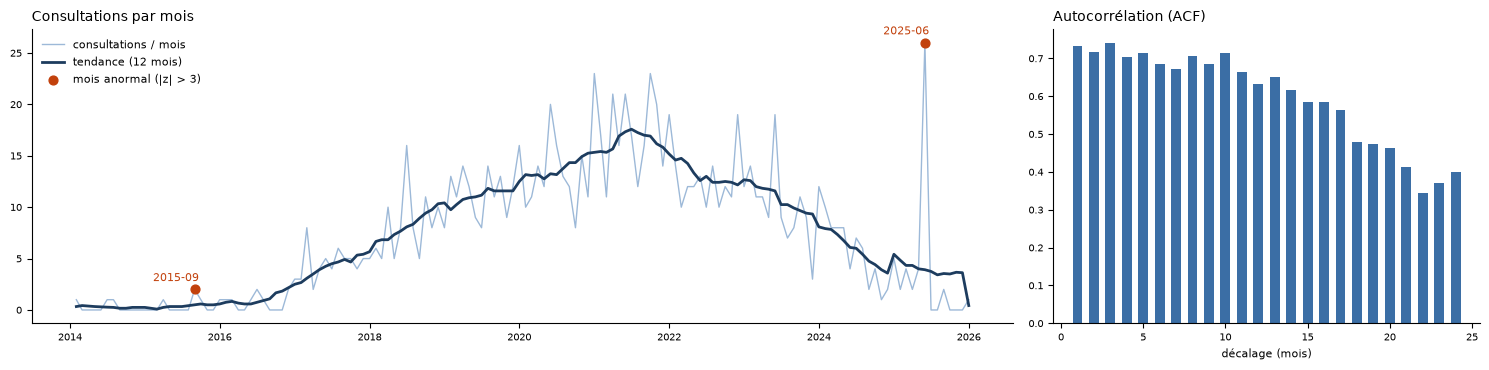

Amplitude de la saisonnalité (écart entre mois) : 4.4 consultations


In [30]:
mensuel = E.set_index("encounter_start").resample("MS").size()
tendance = mensuel.rolling(12, center=True, min_periods=6).mean()
saison = (mensuel - tendance).groupby(mensuel.index.month).mean()
residu = mensuel - tendance - mensuel.index.month.map(saison).values
fen = mensuel.rolling(13, center=True, min_periods=6)
z_glissant = (mensuel - fen.median()) / fen.std()
x = (mensuel - mensuel.mean()).values
acf = [np.corrcoef(x[:-k], x[k:])[0, 1] for k in range(1, 25)]

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2.3, 1]})
axes[0].plot(mensuel.index, mensuel, color="#9db9d8", linewidth=1, label="consultations / mois")
axes[0].plot(tendance.index, tendance, color="#1d3c5e", linewidth=2, label="tendance (12 mois)")
anom = z_glissant[z_glissant.abs() > 3]
axes[0].scatter(anom.index, mensuel[anom.index], color="#c2410c", zorder=3, s=40, label="mois anormal (|z| > 3)")
for d_, v in mensuel[anom.index].items():
    axes[0].annotate(d_.strftime("%Y-%m"), (d_, v), textcoords="offset points", xytext=(-30, 6), fontsize=8, color="#c2410c")
axes[0].legend(fontsize=8, frameon=False); axes[0].set_title("Consultations par mois", fontsize=10, loc="left")
axes[1].bar(range(1, 25), acf, color="#3b6ea5", width=.6)
axes[1].set_xlabel("décalage (mois)", fontsize=8); axes[1].set_title("Autocorrélation (ACF)", fontsize=10, loc="left")
for ax in axes:
    ax.tick_params(labelsize=7)
    for s_ in ["top", "right"]:
        ax.spines[s_].set_visible(False)
plt.tight_layout(); plt.show()
print("Amplitude de la saisonnalité (écart entre mois) :", round(saison.max() - saison.min(), 1), "consultations")

* La série est dominée par une tendance : montée de 2017 à 2021, puis baisse. Elle correspond à l'arrivée des patients, tous inscrits entre 2017 et 2021, à quelques exceptions près.
* L'ACF décroît lentement, sans pic à 12 mois : il n'y a pas de saisonnalité.
* La fenêtre glissante signale juin 2025 : c'est le 20 juin vu au cours 3, qui ressort même sur la série mensuelle. Septembre 2015 est aussi signalé, mais il ne repose que sur 3 consultations.

### 5.3 Chronologie des groupes

In [31]:
debut = E.groupby("groupe")["encounter_start"].agg(["min", "max"]).apply(lambda c: c.dt.date).rename(columns={"min": "première consultation", "max": "dernière consultation"})
mrp_t = PR[PR["procedure_code"] == "MRP-42"].assign(année=lambda d: pd.to_datetime(d["performed_time"]).dt.year)
display(debut)
display(pd.crosstab(mrp_t["authorization_class"], mrp_t["année"]))

,première consultation,dernière consultation
groupe,,
ELITE,2014-02-18,2025-03-05
PHENO,2017-02-05,2026-01-11
RAJEUNI_NON_DECLARE,2016-12-15,2025-06-20
autre,2017-01-20,2025-06-20


année,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
authorization_class,,,,,,,,,,,,
research_restricted,0,0,0,0,0,1,3,3,2,9,2,0
restricted_specialist,1,1,3,3,4,4,3,3,3,1,3,1


* Les dirigeants sont soignés dès 2014, trois ans avant l'arrivée de la population générale (2017). La clinique semble d'abord avoir servi à ce programme.
* Les doses « recherche » (une par patient) ne commencent qu'en 2019, cinq ans après les premières doses données aux dirigeants. Ce n'est donc pas un essai préalable : la « recherche » arrive après coup, et pourrait servir de couverture.

### 5.4 L'effet de chaque dose dans le temps

Pour chaque injection `MRP-42`, on compare l'écart d'âge biologique à la visite juste avant et à la visite juste après.

In [32]:
avec_age = W2.dropna(subset=["ECART_AGE"])
effets = []
doses = PR[PR["procedure_code"] == "MRP-42"].assign(t=lambda d: pd.to_datetime(d["performed_time"])).sort_values("t")
doses["rang"] = doses.groupby("patient_number").cumcount() + 1
for r in doses.itertuples():
    v = avec_age[avec_age["patient_number"] == r.patient_number]
    avant, apres = v[v["encounter_start"] < r.t].tail(1), v[v["encounter_start"] > r.t].head(1)
    if len(avant) and len(apres):
        effets.append((r.patient_number, r.authorization_class, r.rang, apres["ECART_AGE"].iloc[0] - avant["ECART_AGE"].iloc[0]))
effets = pd.DataFrame(effets, columns=["patient", "classe", "rang de la dose", "effet (années)"])
display(effets.groupby(["classe", "rang de la dose"])["effet (années)"].agg(["mean", "min", "max", "count"]).round(1))

mean  min  max  count
classe                rang de la dose                       
research_restricted   1                 0.0 -0.0  0.0      8
restricted_specialist 1                -3.5 -5.7 -0.3      5
                      2                -3.6 -6.2 -0.9      8
                      3                -3.8 -6.5  1.3      8
                      4                -0.3 -4.6  3.0      5
                      5                 8.2  8.2  8.2      1

* Chez les dirigeants, chacune des 3 premières doses rajeunit d'environ 3,5 ans, effet mesuré environ 35 jours après la dose.
* À partir de la 4e dose, l'effet disparaît ou s'inverse. Par exemple, le chef de gouvernement « re-vieillit » de 8 ans après sa 5e dose en 2024. Le traitement pourrait perdre son efficacité, ou provoquer un rebond.
* Les 20 doses « recherche » n'ont aucun effet (0,0 an). Placebo ou dose fictive : dans tous les cas, ce n'est pas le même produit que celui des dirigeants.

### 5.5 Regroupement des trajectoires d'âge (DTW)

Chaque patient a une trajectoire d'écart d'âge sur ses visites. Les trajectoires n'ont ni la même longueur ni les mêmes dates, donc on les compare avec le Dynamic Time Warping (DTW), qui réaligne deux séries avant de les comparer. Chaque trajectoire est ramenée à 0 à la première visite, pour comparer des évolutions et non des niveaux. On applique ensuite une classification hiérarchique sur les distances DTW.

In [33]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

traj = {p_: d.sort_values("encounter_start")["ECART_AGE"].values for p_, d in avec_age.groupby("patient_number")}
traj = {p_: s - s[0] for p_, s in traj.items() if len(s) >= 2}
ids = list(traj)

def dtw(a, b):
    D = np.full((len(a) + 1, len(b) + 1), np.inf)
    D[0, 0] = 0
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            D[i, j] = abs(a[i - 1] - b[j - 1]) + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    return D[-1, -1]

dist = np.zeros((len(ids), len(ids)))
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        dist[i, j] = dist[j, i] = dtw(traj[ids[i]], traj[ids[j]])
groupes_dtw = pd.Series(fcluster(linkage(squareform(dist), "average"), 2, "maxclust"), index=ids)
display(pd.crosstab(groupes_dtw.rename("groupe DTW"), grp.reindex(ids)))

col_0,ELITE,PHENO,RAJEUNI_NON_DECLARE,autre
groupe DTW,,,,
1,0,10,5,212
2,8,0,4,0


Le DTW isole un groupe de 12 trajectoires : les 8 dirigeants et 4 rajeunis non déclarés, sans aucun patient ordinaire. Ces 4 patients ont donc la même évolution que les dirigeants traités, ce qui renforce l'hypothèse d'injections non enregistrées. Les 5 autres rajeunis ont une évolution plus plate, mais un âge biologique déjà bas dès leur première visite.

### 5.6 Le signal cardiaque : deux rythmes indépendants

Les notes cliniques parlent d'une « seconde source pulsatile » dans le thorax. On le vérifie sur les 44 enregistrements ECG (2 canaux). Sur chaque canal, on détecte les battements (pics du signal), on en déduit la fréquence cardiaque, puis on mesure la part de battements synchrones entre les deux canaux (pics à moins de 50 ms d'écart).

In [34]:
from scipy.signal import find_peaks

SIG = pd.read_csv(D / "cardiac_signal_samples.csv")
battements = []
for r in CR.itertuples():
    s = SIG[SIG["recording_id"] == r.recording_id].sort_values("time_ms")
    t = s["time_ms"].values / 1000
    pics = {c: t[find_peaks(s[c].values, height=.9, distance=int(.3 * r.sampling_rate_hz))[0]]
            for c in ["channel_a_normalized", "channel_b_normalized"]}
    a, b = pics.values()
    battements.append({"enregistrement": r.recording_id, "patient": r.patient_number, "contexte": r.recording_context,
                       "bpm canal A": round(60 / np.median(np.diff(a))), "bpm canal B": round(60 / np.median(np.diff(b))),
                       "battements synchrones": round(np.mean([np.min(np.abs(b - x)) < .05 for x in a]), 2)})
battements = pd.DataFrame(battements)
battements["groupe"] = battements["patient"].map(grp)
display(battements.groupby("groupe")["battements synchrones"].agg(["mean", "min", "max", "count"]).round(2))
display(battements.sort_values("battements synchrones").head(12))

,mean,min,max,count
groupe,,,,
ELITE,1.00,0.98,1.00,4
PHENO,0.18,0.13,0.27,8
RAJEUNI_NON_DECLARE,1.00,1.00,1.00,1
autre,0.89,0.30,1.00,31


,enregistrement,patient,contexte,bpm canal A,bpm canal B,battements synchrones,groupe
2,CRD-410025,PAT-31040,rest,80,99,0.13,PHENO
4,CRD-410014,PAT-31233,rest,74,90,0.14,PHENO
6,CRD-410005,PAT-31065,technical_repeat,67,100,0.15,PHENO
0,CRD-410031,PAT-31162,rest,70,88,0.15,PHENO
3,CRD-410016,PAT-31115,rest,86,81,0.17,PHENO
1,CRD-410019,PAT-31162,technical_repeat,71,88,0.17,PHENO
7,CRD-410022,PAT-31037,rest,71,97,0.24,PHENO
5,CRD-410038,PAT-31065,rest,66,99,0.27,PHENO
43,CRD-410028,PAT-31211,technical_repeat,72,54,0.30,autre
41,CRD-410017,PAT-31130,technical_repeat,71,56,0.32,autre


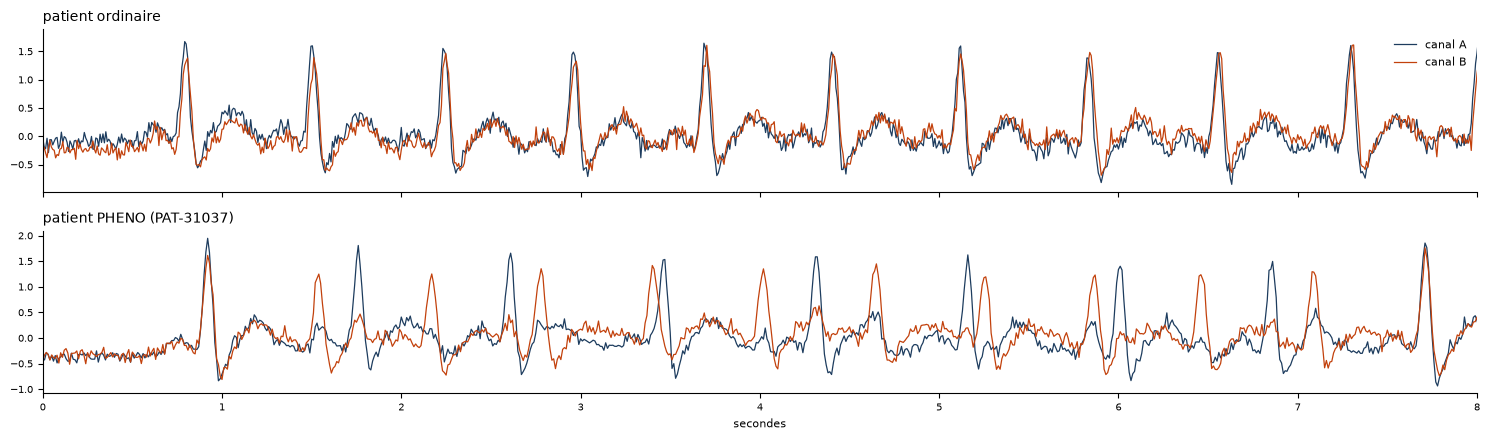

In [35]:
exemples = [("CRD-410034", "patient ordinaire"), ("CRD-410022", "patient PHENO (PAT-31037)")]
fig, axes = plt.subplots(2, 1, figsize=(15, 4.5), sharex=True)
for ax, (rec, titre) in zip(axes, exemples):
    s = SIG[SIG["recording_id"] == rec]
    ax.plot(s["time_ms"] / 1000, s["channel_a_normalized"], color="#1d3c5e", linewidth=.9, label="canal A")
    ax.plot(s["time_ms"] / 1000, s["channel_b_normalized"], color="#c2410c", linewidth=.9, label="canal B")
    ax.set_title(titre, fontsize=10, loc="left"); ax.set_xlim(0, 8); ax.tick_params(labelsize=7)
    for s_ in ["top", "right"]:
        ax.spines[s_].set_visible(False)
axes[0].legend(fontsize=8, frameon=False, loc="upper right"); axes[1].set_xlabel("secondes", fontsize=8)
plt.tight_layout(); plt.show()

* Chez les patients ordinaires et les dirigeants, les deux canaux battent ensemble : presque toujours 100 % de battements synchrones, et jamais moins de 73 % en dehors des appareils défaillants décrits plus bas.
* Chez les 6 patients PHENO qui ont un ECG (8 enregistrements), seuls 13 à 27 % des battements sont synchrones. Les deux canaux battent chacun à leur propre rythme, avec 16 à 33 battements par minute d'écart. Les pics se décalent puis se rejoignent régulièrement, comme on le voit sur le graphique. Cela ressemble à deux cœurs qui battent séparément.
* Les rares autres enregistrements peu synchrones (30 à 47 %) sont tous des « technical repeats » marqués « artefact » ou « interférence ». Leur canal B perd des battements au lieu d'en avoir plus : c'est un défaut d'appareil, pas un second rythme.
* `PAT-31209`, la patiente ordinaire qui avait le plus fort écart de pouls (cours 1), est parfaitement synchrone : chez elle, c'est une arythmie ordinaire. C'est un cas témoin, ce qui confirme que le phénomène PHENO est autre chose.

### 5.7 Bilan

Pas d'effet géographique. Le programme commence en 2014, la « recherche » en 2019 et sans effet. Le DTW rapproche 4 rajeunis non déclarés des dirigeants, et l'ECG montre deux rythmes cardiaques chez les patients PHENO.

## Cours 6 : Miner du texte

Le dossier contient 30 notes cliniques, en anglais. On leur applique la chaîne du cours :
1. préparation (minuscules, suppression de la ponctuation, des identifiants et des mots vides) ;
2. fréquences et n-grammes ;
3. TF-IDF et similarité entre notes ;
4. thèmes (LDA) ;
5. recherche d'entités et de mots-clés.

### 6.1 Préparation, fréquences et n-grammes

In [36]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import LatentDirichletAllocation

notes = N.sort_values("document_id").reset_index(drop=True)
notes["groupe"] = notes["patient_number"].map(grp)

def preparer(texte):
    t = re.sub(r"(pat|enc)-\d+", " ", texte.lower())          # identifiants retirés
    t = re.sub(r"[^a-z\s-]", " ", t)                             # ponctuation et chiffres
    return " ".join(w for w in t.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2)

notes["propre"] = notes["text"].map(preparer)
print("Mots par note après préparation :", notes["propre"].str.split().str.len().describe()[["min", "50%", "max"]].to_dict())
ngr = CountVectorizer(ngram_range=(2, 3), min_df=2).fit(notes["propre"])
display(pd.Series(np.asarray(ngr.transform(notes["propre"]).sum(axis=0))[0], ngr.get_feature_names_out())
        .sort_values(ascending=False).head(6).rename("occurrences").to_frame())

Mots par note après préparation : {'min': 81.0, '50%': 124.0, 'max': 180.0}


,occurrences
follow up,59
available clinical team,42
record concerns,42
observations available,42
limited observations,42
observations available clinical,42


Les n-grammes les plus fréquents (« observations available clinical team », « reviewed prior visits »…) apparaissent 42 fois sur 30 notes. Ce sont des phrases toutes faites, recopiées d'une note à l'autre : la plupart des notes sont générées à partir de gabarits.

### 6.2 TF-IDF : quelles notes sont différentes des autres ?

On représente chaque note par un vecteur TF-IDF (mots et paires de mots), puis on calcule pour chacune sa similarité cosinus avec la note la plus proche. Une note issue d'un gabarit a forcément une « jumelle ».

In [37]:
tfidf = TfidfVectorizer(ngram_range=(1, 2))
X_txt = tfidf.fit_transform(notes["propre"])
sim = cosine_similarity(X_txt)
np.fill_diagonal(sim, np.nan)
notes["similarité max"] = np.nanmax(sim, axis=1).round(2)
vocab = np.array(tfidf.get_feature_names_out())
notes["mots-clés TF-IDF"] = [", ".join(vocab[X_txt[i].toarray()[0].argsort()[::-1][:6]]) for i in range(len(notes))]
display(notes.sort_values("similarité max")[["document_id", "patient_number", "groupe", "title", "similarité max", "mots-clés TF-IDF"]].head(7))

,document_id,patient_number,groupe,title,similarité max,mots-clés TF-IDF
3,CLN-510025,PAT-31065,PHENO,Restricted Phenotype and Public-Identity Resol...,0.10,"public, resolution, consultation, does, attrib..."
4,CLN-510027,PAT-31065,PHENO,Targeted Thoracic Imaging Review,0.10,"contractile, study, spatially, sources, domina..."
12,CLN-510064,PAT-31012,PHENO,Persistent Multisystem Follow-up,0.10,"ocular, vestibular, ocular tracking, gait, rhy..."
10,CLN-510055,PAT-31115,PHENO,Consultation on Recurrent Capture Discrepancies,0.10,"camera, thermal, facial, discrepancy, independ..."
16,CLN-510093,PAT-31222,autre,Occupational Health Assessment 22,0.64,"medical clearance, travel medical, pre travel,..."
13,CLN-510081,PAT-31074,ELITE,Clinical Summary 06,0.66,"pre travel, travel medical, pre, medical, medi..."
24,CLN-510117,PAT-31014,autre,Occupational Health Assessment 26,0.66,"check, post, rhythm check, post viral, viral r..."


Quatre notes sortent nettement du lot : leur similarité maximale est de 0,10, contre 0,64 à 0,83 pour toutes les autres. Ce sont les seules notes écrites « à la main », et elles concernent toutes des patients PHENO (`PAT-31065` deux fois, `PAT-31115`, `PAT-31012`). Leurs mots-clés TF-IDF résument leur contenu :
* imagerie : « contractile, spatially, sources, dominant » ;
* caméra : « camera, thermal, facial, discrepancy » ;
* suivi : « ocular, vestibular, gait, rhythm » ;
* identité : « public identity, resolution, attribute ».

### 6.3 Les phrases uniques : ce qui a été ajouté aux gabarits

On découpe chaque note en phrases et on garde celles qui n'apparaissent que dans une seule note, sans compter les quatre notes manuscrites ni la première ligne des gabarits (qui ne fait que reprendre le motif de la consultation).

In [38]:
phrases = []
for r in notes.itertuples():
    for ph in re.split(r"(?<=[.])\s+|\n", r.text):
        ph = re.sub(r"(PAT|ENC)-\d+", "#", ph.strip())
        if len(ph) > 25 and not ph.isupper():
            phrases.append((r.document_id, r.patient_number, r.groupe, ph))
phrases = pd.DataFrame(phrases, columns=["note", "patient", "groupe", "phrase"])
phrases["nb notes"] = phrases["phrase"].map(phrases.groupby("phrase")["note"].nunique())
manuscrites = notes.loc[notes["similarité max"] < .3, "document_id"]
gabarit_intro = r"^(Clinical summary for|Occupational assessment for|Follow-up for|Specialist review for|Imaging for)"
ajouts = phrases[(phrases["nb notes"] == 1) & ~phrases["note"].isin(manuscrites) & ~phrases["phrase"].str.match(gabarit_intro)]
with pd.option_context("display.max_colwidth", 200):
    display(ajouts)

,note,patient,groupe,phrase,nb notes
145,CLN-510039,PAT-31103,autre,Appearance control settings on the camera were restored to default; the prior mismatch resolved after calibration.,1
414,CLN-510126,PAT-31099,ELITE,The phrase dual cardiac structures was entered in the preliminary worksheet but rejected after the apparent second contour disappeared on repeat positioning.,1


Seulement deux phrases ont été ajoutées aux gabarits, et elles jouent toutes les deux le rôle de cas témoins :
* `PAT-31103` (patient ordinaire) : le problème de caméra a disparu après calibrage, et sa confiance caméra est normale (79). C'est une vraie panne d'appareil, que les médecins distinguent du « décalage de capture » persistant décrit chez `PAT-31115` ;
* `PAT-31099` (la patiente décédée) : l'hypothèse « dual cardiac structures » a été notée puis rejetée, et son ECG est en effet parfaitement synchrone (cours 5). C'est une fausse piste écartée.

### 6.4 Thèmes (LDA)

In [39]:
cv = CountVectorizer().fit(notes["propre"])
lda = LatentDirichletAllocation(4, random_state=0).fit(cv.transform(notes["propre"]))
mots = np.array(cv.get_feature_names_out())
display(pd.DataFrame({f"thème {t}": mots[c.argsort()[::-1][:8]] for t, c in enumerate(lda.components_)}))
display(pd.crosstab(notes["groupe"], lda.transform(cv.transform(notes["propre"])).argmax(axis=1), colnames=["thème dominant"]))

,thème 0,thème 1,thème 2,thème 3
0,identity,source,ordinary,patient
1,ocular,study,assessment,assessment
2,public,second,visits,up
3,record,repeat,history,follow
4,does,peripheral,technical,clinical
5,consultation,patient,medication,measurements
6,resolution,review,functional,findings
7,independent,imaging,available,ordinary


thème dominant,0,1,2,3
groupe,,,,
ELITE,0,0,0,3
PHENO,2,2,0,4
RAJEUNI_NON_DECLARE,0,0,0,1
autre,0,0,6,12


La LDA retrouve deux thèmes « routiniers » (gabarits) et deux thèmes propres aux patients PHENO : un thème « identité / public / oculaire / indépendant » et un thème « source / seconde / imagerie / mouvement ». Aucune note de dirigeant, de rajeuni ou de patient ordinaire n'a pour thème principal l'un de ces deux.

### 6.5 Entités et mots-clés

In [40]:
entites = Counter(m for t in notes["text"] for m in re.findall(r"\b([A-Z][a-z]+ [A-Z][a-z]+)\b", t)
                  if not re.match(r"^(The|No|Repeat|Standard|Ocular|Peripheral|Public|Each|During|Two|Cardiac|Short|Walking|Annual|Fit|Continue|Targeted)\b", m))
print("Noms propres (deux mots capitalisés) :", entites.most_common(5))
cles = ["public identity", "species", "internal designation", "dual cardiac", "second, smaller source", "appearance control", "partly independent"]
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame([(c, ", ".join(dict.fromkeys(notes.loc[notes["text"].str.contains(c, case=False), "patient_number"]))) for c in cles],
                         columns=["expression", "patients concernés"]))

Noms propres (deux mots capitalisés) : [('Elias Voss', 1)]


,expression,patients concernés
0,public identity,PAT-31065
1,species,PAT-31065
2,internal designation,PAT-31065
3,dual cardiac,"PAT-31065, PAT-31099"
4,"second, smaller source",PAT-31065
5,appearance control,"PAT-31103, PAT-31115"
6,partly independent,"PAT-31065, PAT-31012"


* Un seul nom propre de personne apparaît dans tout le dossier : « Elias Voss ». La note de `PAT-31065` explique qu'elle relie ce numéro de patient à cette identité publique en croisant plusieurs attributs non secrets : tranche de date de naissance, région, orientation « executive health », historique des cliniques, rôle public et dates de nomination. `PAT-31065` est donc une personnalité publique, enregistrée ici comme « clinical specialist ».
* La même note précise que le dossier « n'établit ni une classification d'espèce, ni une désignation interne ». Ces hypothèses ont donc au moins été envisagées.
* Les autres expressions (« second, smaller source », « partly independent », « appearance control ») ne concernent que des patients PHENO, en dehors des deux cas témoins vus plus haut.

### 6.6 Le texte contredit-il les données ?

In [41]:
pheno_gabarit = notes[(notes["groupe"] == "PHENO") & (notes["similarité max"] > .3)]
display(pheno_gabarit[["document_id", "patient_number", "title"]]
        .join(feat[["ECART_POULS", "N_DISCORDANT", "N_OCULAR_ATYP", "CAMMATCH"]].round(1), on="patient_number")
        .assign(conclusion_de_la_note=pheno_gabarit["text"].str.extract(r"(most consistent with [a-z ]+)")[0]))

,document_id,patient_number,title,ECART_POULS,N_DISCORDANT,N_OCULAR_ATYP,CAMMATCH,conclusion_de_la_note
0,CLN-510009,PAT-31012,Clinical Summary 03,16.2,3.0,3.0,55.0,most consistent with routine variation and the...
1,CLN-510010,PAT-31037,Clinical Summary 04,27.0,5.0,4.0,68.0,most consistent with routine variation and the...
19,CLN-510107,PAT-31115,Clinical Summary 01,14.5,3.0,2.0,72.2,most consistent with routine variation and the...
21,CLN-510113,PAT-31215,Clinical Summary 02,26.3,6.0,0.0,82.6,most consistent with routine variation and the...


Quatre patients PHENO ont aussi des notes issues des gabarits, qui concluent à une « variation de routine ». Leurs mesures disent l'inverse : écart de pouls de 15 à 27 bpm, 3 à 6 pouls « discordants », suivi oculaire souvent atypique, caméra souvent basse. Les notes « officielles » minimisent donc ce que les mesures et les notes restreintes décrivent. Le texte et les données ne disent pas la même chose, ce qui fait penser à une dissimulation.

### 6.7 Bilan

Les 4 notes écrites à la main concernent toutes des patients PHENO, et les notes de routine de ces patients minimisent ce que montrent leurs mesures.

## Synthèse

Le résumé des résultats et les pistes pour les autres dossiers sont dans le rapport `03_rapport_health.ipynb`. En bref, on trouve deux phénomènes qui ne touchent jamais les mêmes patients :
* un programme d'injections `MRP-42` pour 8 dirigeants depuis 2014, et 9 autres patients qui rajeunissent de la même façon sans acte enregistré ;
* 10 patients avec deux rythmes cardiaques, des yeux qui bougent séparément et une identité instable à la caméra.

Ce sont des corrélations, sur des données synthétiques : plusieurs indices vont dans le même sens, mais rien n'est prouvé.